# Stage 10C — Molecular SHAP highlighting for representative activity ranges

This notebook maps the strongest Morgan-bit SHAP contributions onto test-molecule structures and lists important non-Morgan descriptor contributions beside each structure. Every mapped Morgan bit has its own color, and the legend reports its signed contribution, direction, and number of mapped environments.

For **each** final model (ExtraTrees and CatBoost), it selects 10 molecules with the lowest predicted pIC50, 10 molecules in the middle of the prediction ranking centered on the median, and 10 molecules with the highest predicted pIC50. This gives 30 molecules per model and 60 total. Cases are selected using predicted pIC50 only. The actual pIC50 values saved by Stage 08 are shown beside the predictions for reporting; they do not affect selection, fitting, or tuning.

The notebook uses the exact fixed 250 Stage 05 features. It reads the saved Stage 10 SHAP values and reads only those 250 columns from the Stage 03 feature parquet to obtain raw feature values for the selected molecules. It does not load the 3,291-feature pool into memory, refit models, or reselect features. Each figure is displayed as it runs and saved as SVG and 300-dpi PNG under `outputs/10c_molecular_highlighting/`.


In [16]:
# 1. Find the project and import the packages for this notebook.
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "src").is_dir():
    raise FileNotFoundError("Open this notebook from the BRD4 QSAR project folder.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import html
import re
import numpy as np
import pandas as pd
from IPython.display import display, SVG, Image as IPyImage
from rdkit import Chem
from rdkit.Chem import rdFingerprintGenerator
from rdkit.Chem.Draw import rdMolDraw2D
from PIL import Image, ImageDraw, ImageFont
from io import BytesIO

from src.utils import OUTPUTS, load_config, write_manifest

MODELS = ["ExtraTreesRegressor", "CatBoostRegressor"]
SHAP_DIR = OUTPUTS / "10_shap_interpretation"
OUT_DIR = OUTPUTS / "10c_molecular_highlighting"
TABLE_DIR = OUT_DIR / "tables"
FIGURE_DIR = OUT_DIR / "figures"
TABLE_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print(f"Project: {PROJECT_ROOT}")
print(f"10C output folder: {OUT_DIR}")
print("Next: check that Stage 05, Stage 08, and Stage 10 outputs are available.")

Project: c:\Users\USER\Documents\E\Code
10C output folder: C:\Users\USER\Documents\E\Code\outputs\10c_molecular_highlighting
Next: check that Stage 05, Stage 08, and Stage 10 outputs are available.


In [17]:
# 2. Check the fixed-250 features, saved SHAP values, predictions, and structures.
from src.utils import load_config

SELECTED_FILE = OUTPUTS / "05_feature_selection/tables/selected_features.csv"
TEST_IDS_FILE = OUTPUTS / "04_train_test_split/tables/test_ids.csv"
CLEANED_FILE = OUTPUTS / "02_clean_data/tables/cleaned_activity.csv"
FEATURES_FILE = OUTPUTS / "03_feature_generation/tables/all_features.parquet"
PREDICTIONS_FILE = OUTPUTS / "08_final_model_evaluation/tables/locked_test_predictions_all_models.csv"

required = [SELECTED_FILE, TEST_IDS_FILE, CLEANED_FILE, FEATURES_FILE, PREDICTIONS_FILE]
required += [SHAP_DIR / "tables" / f"test_shap_values_{m}.parquet" for m in MODELS]
missing = [p for p in required if not p.is_file()]
if missing:
    raise FileNotFoundError(
        "Missing prerequisite output(s):\n" + "\n".join(map(str, missing))
        + "\nRun Stages 03, 04, 05, 08, and 10 first."
    )

cfg = load_config()
FP_SIZE = int(cfg.get("fingerprint_bits", 2048))
FP_RADIUS = int(cfg.get("fingerprint_radius", 2))
USE_CHIRALITY = bool(cfg.get("use_chirality", True))
MORGAN = rdFingerprintGenerator.GetMorganGenerator(
    radius=FP_RADIUS,
    fpSize=FP_SIZE,
    includeChirality=USE_CHIRALITY,
)

selected_features = pd.read_csv(SELECTED_FILE)["feature"].astype(str).tolist()
if len(selected_features) != 250 or len(set(selected_features)) != 250:
    raise ValueError(
        f"Expected exactly 250 unique Stage 05 features; found {len(selected_features)}."
    )

test_ids = pd.read_csv(TEST_IDS_FILE, dtype={"chembl_id": str})
test_ids["chembl_id"] = test_ids.chembl_id.astype(str)
if test_ids.chembl_id.duplicated().any():
    raise ValueError("Duplicate IDs found in the locked test ID file.")

structures = pd.read_csv(
    CLEANED_FILE,
    usecols=["chembl_id", "canonical_smiles"],
    dtype={"chembl_id": str},
)
structures["chembl_id"] = structures.chembl_id.astype(str)
if structures.chembl_id.duplicated().any():
    raise ValueError("Duplicate molecule IDs found in cleaned structure data.")
smiles_by_id = structures.set_index("chembl_id").canonical_smiles
if set(test_ids.chembl_id) - set(smiles_by_id.index):
    raise ValueError("Some test molecules have no canonical SMILES in cleaned data.")

predictions = pd.read_csv(PREDICTIONS_FILE, dtype={"chembl_id": str})
predictions["chembl_id"] = predictions.chembl_id.astype(str)
required_prediction_columns = {"model", "chembl_id", "predicted_pIC50", "observed_pIC50"}
missing_prediction_columns = required_prediction_columns - set(predictions.columns)
if missing_prediction_columns:
    raise ValueError(f"Stage 08 predictions are missing columns: {sorted(missing_prediction_columns)}")
predictions = predictions.loc[predictions.model.isin(MODELS)].copy()

# Read only the selected 250 columns from the Stage 03 parquet. These raw values
# are needed to label the local SHAP features; the remaining feature columns are
# not loaded.
X_test_fixed250 = pd.read_parquet(FEATURES_FILE, columns=selected_features)
X_test_fixed250.index = X_test_fixed250.index.astype(str)
missing_test_ids = set(test_ids.chembl_id) - set(X_test_fixed250.index)
if missing_test_ids:
    raise ValueError(
        f"{len(missing_test_ids)} locked test IDs are absent from the feature table."
    )
X_test_fixed250 = X_test_fixed250.reindex(test_ids.chembl_id)
X_test_fixed250 = X_test_fixed250.apply(pd.to_numeric, errors="coerce")
if not np.isfinite(X_test_fixed250.to_numpy(dtype=float)).all():
    raise ValueError(
        "One or more selected fixed-250 test features are missing or infinite. "
        "No imputation is used in this workflow."
    )

print(f"Fixed Stage 05 feature columns loaded: {X_test_fixed250.shape[1]}")
print(f"Locked test molecules: {len(test_ids):,}")
print("Planned examples: 10 lowest + 10 median-centered + 10 highest per model.")
print("RDKit Morgan settings match training: "
      f"radius={FP_RADIUS}, bits={FP_SIZE}, chirality={USE_CHIRALITY}")
print("Actual pIC50 is read from Stage 08 predictions for figure/table labels only.")
print("Example selection remains based on predicted pIC50 only; actual values are not used to select, fit, or tune models.")
print("Next: validate the saved SHAP values against the fixed 250 features.")


Fixed Stage 05 feature columns loaded: 250
Locked test molecules: 1,283
Planned examples: 10 lowest + 10 median-centered + 10 highest per model.
RDKit Morgan settings match training: radius=2, bits=2048, chirality=True
Actual pIC50 is read from Stage 08 predictions for figure/table labels only.
Example selection remains based on predicted pIC50 only; actual values are not used to select, fit, or tune models.
Next: validate the saved SHAP values against the fixed 250 features.


In [18]:
# 3. Validate the saved SHAP values and align them with the fixed feature set.
morgan_features = [name for name in selected_features if name.startswith("ecfp4_")]
descriptor_features = [name for name in selected_features if not name.startswith("ecfp4_")]
print(f"Morgan bits among fixed 250: {len(morgan_features)}")
print(f"Non-Morgan descriptors among fixed 250: {len(descriptor_features)}")
if not morgan_features:
    raise ValueError(
        "No Morgan bits are present in the fixed Stage 05 features; "
        "structural Morgan highlighting is not possible for this feature list."
    )

shap_by_model = {}
for model_name in MODELS:
    frame = pd.read_parquet(
        SHAP_DIR / "tables" / f"test_shap_values_{model_name}.parquet"
    )
    if "chembl_id" not in frame.columns:
        raise ValueError(f"SHAP table for {model_name} has no chembl_id column.")
    frame["chembl_id"] = frame.chembl_id.astype(str)
    if frame.chembl_id.duplicated().any():
        raise ValueError(f"SHAP table for {model_name} contains duplicate IDs.")
    if set(frame.chembl_id) != set(test_ids.chembl_id):
        raise ValueError(
            f"SHAP IDs for {model_name} do not match the locked test IDs."
        )
    absent = set(selected_features) - set(frame.columns)
    if absent:
        raise ValueError(
            f"SHAP table for {model_name} is missing fixed Stage 05 features: "
            f"{sorted(absent)[:10]}"
        )
    frame = (
        frame.set_index("chembl_id")
        .reindex(test_ids.chembl_id)
        .loc[:, selected_features]
    )
    if not np.isfinite(frame.to_numpy(dtype=float)).all():
        raise ValueError(f"SHAP values for {model_name} contain missing or infinite values.")
    shap_by_model[model_name] = frame
    print(
        f"{model_name}: {frame.shape[0]:,} molecules × "
        f"{frame.shape[1]} saved SHAP features"
    )

print("Raw fixed-250 feature values and all test-molecule SHAP rows are ready.")
print("Next: define Morgan environment mapping and figure-drawing functions.")


Morgan bits among fixed 250: 103
Non-Morgan descriptors among fixed 250: 147
ExtraTreesRegressor: 1,283 molecules × 250 saved SHAP features
CatBoostRegressor: 1,283 molecules × 250 saved SHAP features
Raw fixed-250 feature values and all test-molecule SHAP rows are ready.
Next: define Morgan environment mapping and figure-drawing functions.


In [19]:
# 4. Define RDKit Morgan environment mapping and drawing helpers.
import xml.etree.ElementTree as ET
# Each present Morgan bit gets a distinct color. The legend gives its direction.
BIT_PALETTE = [
    "#1f77b4", "#ff7f0e", "#2ca02c", "#d62728",
    "#9467bd", "#8c564b", "#e377c2", "#17becf",
    "#bcbd22", "#393b79", "#637939", "#843c39",
]
CANVAS_W, CANVAS_H = 1180, 660
MOL_W, MOL_H = 660, 580
TOP_N = 12

def bit_environments(mol):
    """Return RDKit's hashed Morgan bit -> (center atom, radius) occurrences."""
    ao = rdFingerprintGenerator.AdditionalOutput()
    ao.AllocateBitInfoMap()
    MORGAN.GetFingerprint(mol, additionalOutput=ao)
    return dict(ao.GetBitInfoMap())

def environment_atoms_bonds(mol, occurrences):
    atoms, bonds = set(), set()
    for center, radius in occurrences:
        center, radius = int(center), int(radius)
        atoms.add(center)
        for bond_idx in Chem.FindAtomEnvironmentOfRadiusN(mol, radius, center):
            bond = mol.GetBondWithIdx(int(bond_idx))
            bonds.add(int(bond_idx))
            atoms.update((bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()))
    return atoms, bonds

def hex_to_rgba(hex_colour, alpha=0.78):
    """Convert a hex color to the normalized RGBA tuple expected by RDKit."""
    value = hex_colour.lstrip("#")
    rgb = tuple(int(value[i:i + 2], 16) / 255 for i in (0, 2, 4))
    return (*rgb, alpha)


def safe_stem(text):
    return re.sub(r"[^A-Za-z0-9_.-]+", "_", str(text)).strip("_")

def draw_shap_molecule(mol, model_name, case_label, chembl_id, predicted, actual, baseline, shap_row, local_shap_rows):
    model_short = {"ExtraTreesRegressor": "ExtraTrees", "CatBoostRegressor": "CatBoost"}.get(model_name, model_name)
    # Stage 10 already saved the strongest local contributions and their raw
    # feature values for this exact fixed-250 model and molecule.
    ranked_local = local_shap_rows.sort_values("abs_shap", ascending=False, kind="stable")
    if ranked_local.empty:
        raise ValueError(f"No saved local SHAP rows for {model_name}/{case_label}/{chembl_id}.")
    top_entries = [
        (str(row.feature), float(row.shap_value), float(row.feature_value))
        for row in ranked_local.head(TOP_N).itertuples(index=False)
    ]

    bit_info = bit_environments(mol)
    mapped_bits = []
    descriptor_entries = []
    for feat, shap_value, raw_value in top_entries:
        if feat.startswith("ecfp4_"):
            bit = int(feat.rsplit("_", 1)[1])
            if bit in bit_info:
                atoms, bonds = environment_atoms_bonds(mol, bit_info[bit])
                if atoms:
                    mapped_bits.append(
                        (feat, bit, shap_value, raw_value, atoms, bonds, len(bit_info[bit]))
                    )
        else:
            descriptor_entries.append((feat, shap_value, raw_value))

    # If the top 12 contain few descriptors, show the next strongest non-Morgan
    # contributions too, so the side panel remains informative.
    if len(descriptor_entries) < 5:
        seen = {item[0] for item in descriptor_entries}
        for row in ranked_local.iloc[TOP_N:].itertuples(index=False):
            feat = str(row.feature)
            if feat.startswith("ecfp4_") or feat in seen:
                continue
            descriptor_entries.append((feat, float(row.shap_value), float(row.feature_value)))
            seen.add(feat)
            if len(descriptor_entries) == 5:
                break

    if len(mapped_bits) > len(BIT_PALETTE):
        raise ValueError(
            f"Found {len(mapped_bits)} Morgan bits but only "
            f"{len(BIT_PALETTE)} distinct colors are defined."
        )

    # Give every Morgan bit a deterministic, distinct color for this molecule.
    colored_bits = []
    for index, item in enumerate(mapped_bits):
        feat, bit, value, raw, atoms, bonds, n_occurrences = item
        color_hex = BIT_PALETTE[index]
        colored_bits.append(
            (feat, bit, value, raw, atoms, bonds, n_occurrences, color_hex)
        )
    mapped_bits = colored_bits

    # Track overlaps. Shared atoms/bonds show the color for the bit with the
    # strongest absolute SHAP contribution; overlap counts are included below.
    atom_owners, bond_owners = {}, {}
    for feat, bit, value, raw, atoms, bonds, n_occurrences, color_hex in mapped_bits:
        for atom_idx in atoms:
            atom_owners.setdefault(atom_idx, set()).add(bit)
        for bond_idx in bonds:
            bond_owners.setdefault(bond_idx, set()).add(bit)

    atom_choice, bond_choice, overlap_counts = {}, {}, {}
    for feat, bit, value, raw, atoms, bonds, n_occurrences, color_hex in mapped_bits:
        colour = hex_to_rgba(color_hex)
        overlap_counts[bit] = (
            sum(len(atom_owners[a]) > 1 for a in atoms),
            sum(len(bond_owners[b]) > 1 for b in bonds),
        )
        for atom_idx in atoms:
            if atom_idx not in atom_choice or abs(value) > abs(atom_choice[atom_idx][1]):
                atom_choice[atom_idx] = (colour, value, bit)
        for bond_idx in bonds:
            if bond_idx not in bond_choice or abs(value) > abs(bond_choice[bond_idx][1]):
                bond_choice[bond_idx] = (colour, value, bit)

    atom_colours = {i: item[0] for i, item in atom_choice.items()}
    bond_colours = {i: item[0] for i, item in bond_choice.items()}
    highlight_atoms = sorted(atom_colours)
    highlight_bonds = sorted(bond_colours)

    # Render molecule panel as vector SVG.
    svg_drawer = rdMolDraw2D.MolDraw2DSVG(MOL_W, MOL_H)
    svg_drawer.drawOptions().addAtomIndices = False
    svg_drawer.drawOptions().addBondIndices = False
    svg_drawer.drawOptions().padding = 0.08
    if highlight_atoms:
        svg_drawer.DrawMolecule(mol, highlightAtoms=highlight_atoms, highlightBonds=highlight_bonds,
                                highlightAtomColors=atom_colours, highlightBondColors=bond_colours)
    else:
        svg_drawer.DrawMolecule(mol)
    svg_drawer.FinishDrawing()
    svg_text = svg_drawer.GetDrawingText()
    svg_root_match = re.search(r"<svg\b[^>]*>", svg_text, flags=re.S)
    if not svg_root_match:
        raise ValueError("Could not find the RDKit SVG root element.")

    # Discard RDKit's root tag and wrap its drawing body in a fresh SVG root.
    # This avoids duplicate width/height/viewBox attributes across RDKit versions.
    drawing = svg_text[svg_root_match.end():]
    drawing = re.sub(r"</svg>\s*$", "", drawing, flags=re.S)
    root = (
        f'<svg xmlns="http://www.w3.org/2000/svg" '
        f'xmlns:rdkit="http://www.rdkit.org/xml" '
        f'xmlns:xlink="http://www.w3.org/1999/xlink" '
        f'version="1.1" width="{CANVAS_W}px" height="{CANVAS_H}px" '
        f'viewBox="0 0 {CANVAS_W} {CANVAS_H}" xml:space="preserve">'
    )
    drawing_group = f'<g transform="translate(0,55)">{drawing}</g>'
    lines = [
        f'<text x="24" y="30" font-size="20" font-weight="bold" font-family="Arial,sans-serif" fill="#1a1a2e">{html.escape(model_short)} | {html.escape(case_label)} | {html.escape(str(chembl_id))}</text>',
        f'<text x="24" y="52" font-size="14" font-family="Arial,sans-serif" fill="#444">Predicted pIC50 = {predicted:.3f} | Actual pIC50 = {actual:.3f} | SHAP baseline = {baseline:.3f}</text>',
        '<line x1="680" y1="70" x2="680" y2="625" stroke="#d7d7d7" stroke-width="1"/>',
        '<text x="710" y="96" font-size="17" font-weight="bold" font-family="Arial,sans-serif" fill="#222">Morgan bit environments</text>',
        '<text x="710" y="115" font-size="11" font-family="Arial,sans-serif" fill="#444">+ raises predicted pIC50; - lowers predicted pIC50</text>',
    ]

    # Group legend entries by contribution direction, then sort by magnitude.
    legend_bits = sorted(mapped_bits, key=lambda item: (item[2] < 0, -abs(item[2])))
    legend_start_y = 140
    for index, (feat, bit, value, raw, atoms, bonds, n_occurrences, color_hex) in enumerate(legend_bits):
        y = legend_start_y + index * 20
        sign = "+" if value >= 0 else "-"
        direction = "raises" if value >= 0 else "lowers"
        overlap_atom_count, overlap_bond_count = overlap_counts[bit]
        overlap_text = (
            f"; overlap {overlap_atom_count} atoms/{overlap_bond_count} bonds"
            if overlap_atom_count or overlap_bond_count else ""
        )
        lines.append(
            f'<rect x="710" y="{y - 11}" width="13" height="13" rx="2" fill="{color_hex}"/>'
            f'<text x="731" y="{y}" font-size="11" font-family="Arial,sans-serif" fill="#333">'
            f'Bit {bit} | {sign}{abs(value):.4f} pIC50 | {n_occurrences} env. | {direction}{overlap_text}</text>'
        )

    descriptor_heading_y = max(165, legend_start_y + len(legend_bits) * 20 + 24)
    lines.append(
        f'<text x="710" y="{descriptor_heading_y}" font-size="16" font-weight="bold" '
        f'font-family="Arial,sans-serif" fill="#222">Top non-Morgan contributions</text>'
    )
    for rank, (feat, value, raw) in enumerate(descriptor_entries[:5], start=1):
        y = descriptor_heading_y + 26 + (rank - 1) * 30
        sign = "+" if value >= 0 else "-"
        lines.append(
            f'<text x="710" y="{y}" font-size="11" font-family="Arial,sans-serif" fill="#333">'
            f'{rank}. {html.escape(feat)} | {sign}{abs(value):.4f}</text>'
        )
        lines.append(
            f'<text x="730" y="{y + 14}" font-size="10" font-family="Arial,sans-serif" fill="#555">'
            f'value={raw:.4g} pIC50 contribution</text>'
        )
    if not descriptor_entries:
        lines.append(
            f'<text x="710" y="{descriptor_heading_y + 24}" font-size="11" '
            f'font-family="Arial,sans-serif" fill="#555">'
            f'No non-Morgan features are available in the saved local SHAP rows.</text>'
        )
    lines.append(
        '<text x="24" y="645" font-size="11" font-family="Arial,sans-serif" fill="#555">'
        'Each color identifies a Morgan bit. Shared atoms/bonds use the strongest |SHAP| bit.</text>'
    )
    final_svg = root + drawing_group + "\n".join(lines) + "</svg>"
    ET.fromstring(final_svg)  # Catch malformed SVG before notebook display.

    # Render matching PNG with RDKit's built-in Cairo drawer, then add panel text.
    png_drawer = rdMolDraw2D.MolDraw2DCairo(MOL_W, MOL_H)
    png_drawer.drawOptions().addAtomIndices = False
    png_drawer.drawOptions().addBondIndices = False
    png_drawer.drawOptions().padding = 0.08
    if highlight_atoms:
        png_drawer.DrawMolecule(mol, highlightAtoms=highlight_atoms, highlightBonds=highlight_bonds,
                                highlightAtomColors=atom_colours, highlightBondColors=bond_colours)
    else:
        png_drawer.DrawMolecule(mol)
    png_drawer.FinishDrawing()
    molecule_image = Image.open(BytesIO(png_drawer.GetDrawingText())).convert("RGB")
    canvas = Image.new("RGB", (CANVAS_W, CANVAS_H), "white")
    canvas.paste(molecule_image, (0, 55))
    painter = ImageDraw.Draw(canvas)
    font = ImageFont.load_default()
    painter.text((24, 12), f"{model_short} | {case_label} | {chembl_id}", fill="#1a1a2e", font=font)
    painter.text((24, 36), f"Predicted pIC50={predicted:.3f} | Actual pIC50={actual:.3f} | SHAP baseline={baseline:.3f}", fill="#444444", font=font)
    painter.line((680, 70, 680, 625), fill="#d7d7d7", width=2)
    painter.text((710, 82), "Morgan bit environments", fill="#222222", font=font)
    painter.text((710, 99), "+ raises pIC50; - lowers pIC50", fill="#444444", font=font)

    for index, (feat, bit, value, raw, atoms, bonds, n_occurrences, color_hex) in enumerate(legend_bits):
        y = 119 + index * 19
        sign = "+" if value >= 0 else "-"
        direction = "raises" if value >= 0 else "lowers"
        overlap_atom_count, overlap_bond_count = overlap_counts[bit]
        overlap_text = (
            f"; overlap {overlap_atom_count}A/{overlap_bond_count}B"
            if overlap_atom_count or overlap_bond_count else ""
        )
        painter.rectangle((710, y, 722, y + 12), fill=color_hex)
        painter.text(
            (730, y),
            f"Bit {bit} | {sign}{abs(value):.3f} | {n_occurrences} env. | {direction}{overlap_text}",
            fill="#333333",
            font=font,
        )

    descriptor_heading_y_png = max(145, 119 + len(legend_bits) * 19 + 17)
    painter.text(
        (710, descriptor_heading_y_png),
        "Top non-Morgan contributions",
        fill="#222222",
        font=font,
    )
    for rank, (feat, value, raw) in enumerate(descriptor_entries[:5], start=1):
        y = descriptor_heading_y_png + 20 + (rank - 1) * 30
        sign = "+" if value >= 0 else "-"
        painter.text(
            (710, y),
            f"{rank}. {feat[:42]} | {sign}{abs(value):.3f}",
            fill="#333333",
            font=font,
        )
        painter.text(
            (730, y + 14),
            f"value={raw:.4g} pIC50 contribution",
            fill="#555555",
            font=font,
        )
    painter.text((24, 638), "Unique Morgan-bit colors; shared regions use the strongest |SHAP| bit.", fill="#555555", font=font)
    mapped_bits_with_overlaps = [
        (feat, bit, value, raw, atoms, bonds, n_occurrences, color_hex,
         overlap_counts[bit][0], overlap_counts[bit][1])
        for feat, bit, value, raw, atoms, bonds, n_occurrences, color_hex in mapped_bits
    ]
    return final_svg, canvas, top_entries, mapped_bits_with_overlaps, descriptor_entries

print("Drawing helpers ready: each Morgan bit has its own legend color.")
print("Next: select predicted low, median, and high examples for ExtraTrees.")

Drawing helpers ready: each Morgan bit has its own legend color.
Next: select predicted low, median, and high examples for ExtraTrees.


Rendering 30 ExtraTreesRegressor examples: 10 lowest, 10 median-centered, and 10 highest predictions.
ExtraTreesRegressor | lowest 01/10 | rank 1/1283 | CHEMBL4763815 | predicted pIC50=3.211 | actual pIC50=3.354


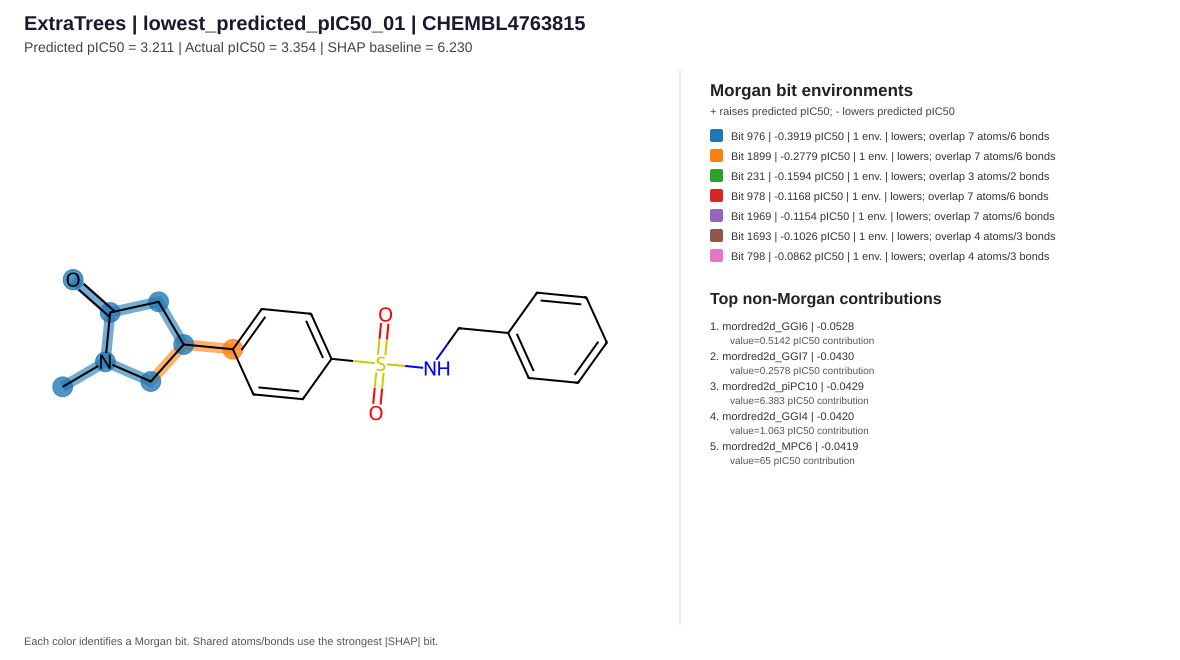

ExtraTreesRegressor | lowest 02/10 | rank 2/1283 | CHEMBL4759311 | predicted pIC50=3.232 | actual pIC50=3.325


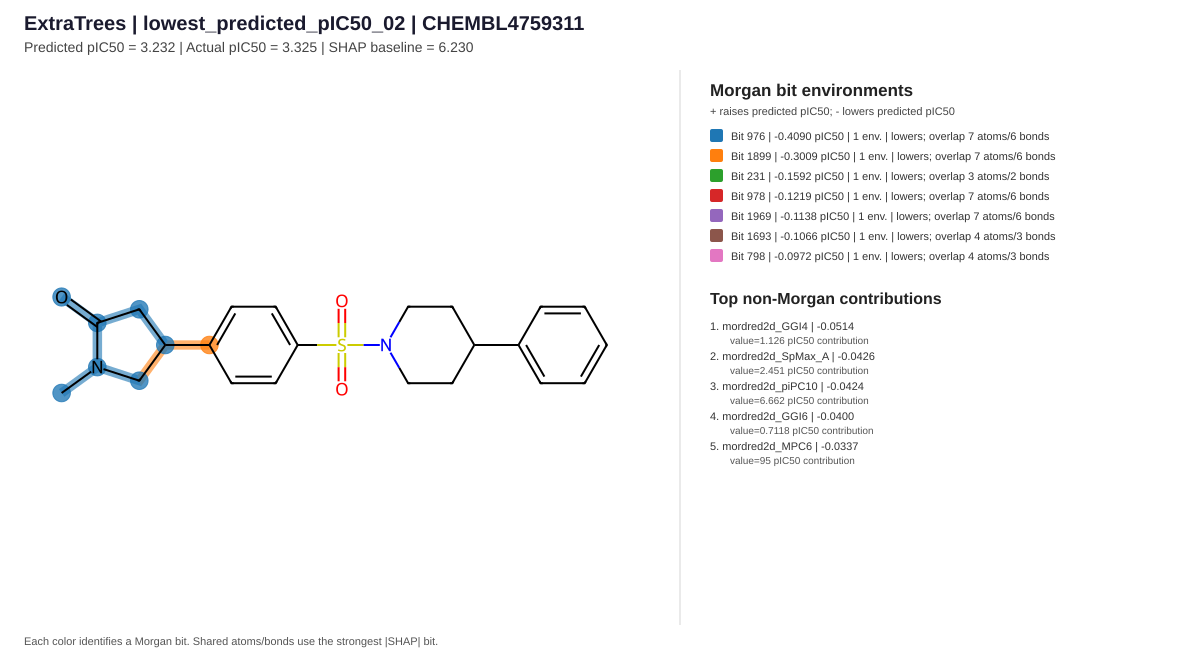

ExtraTreesRegressor | lowest 03/10 | rank 3/1283 | CHEMBL4788775 | predicted pIC50=3.330 | actual pIC50=2.943


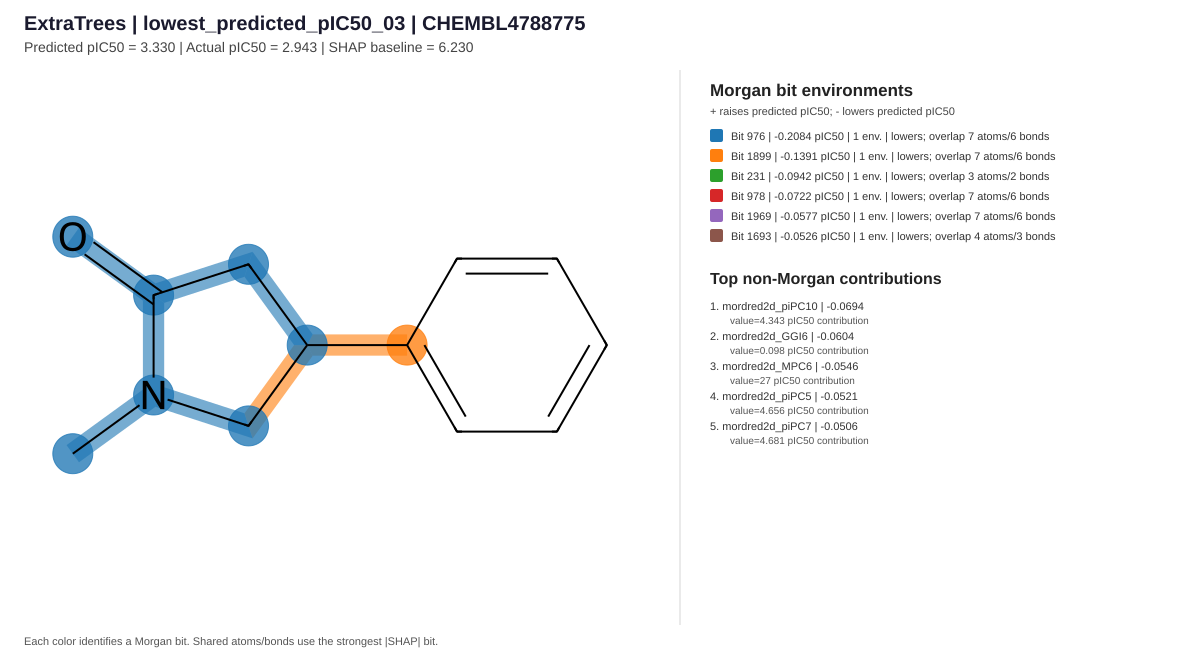

ExtraTreesRegressor | lowest 04/10 | rank 4/1283 | CHEMBL4764375 | predicted pIC50=3.330 | actual pIC50=2.845


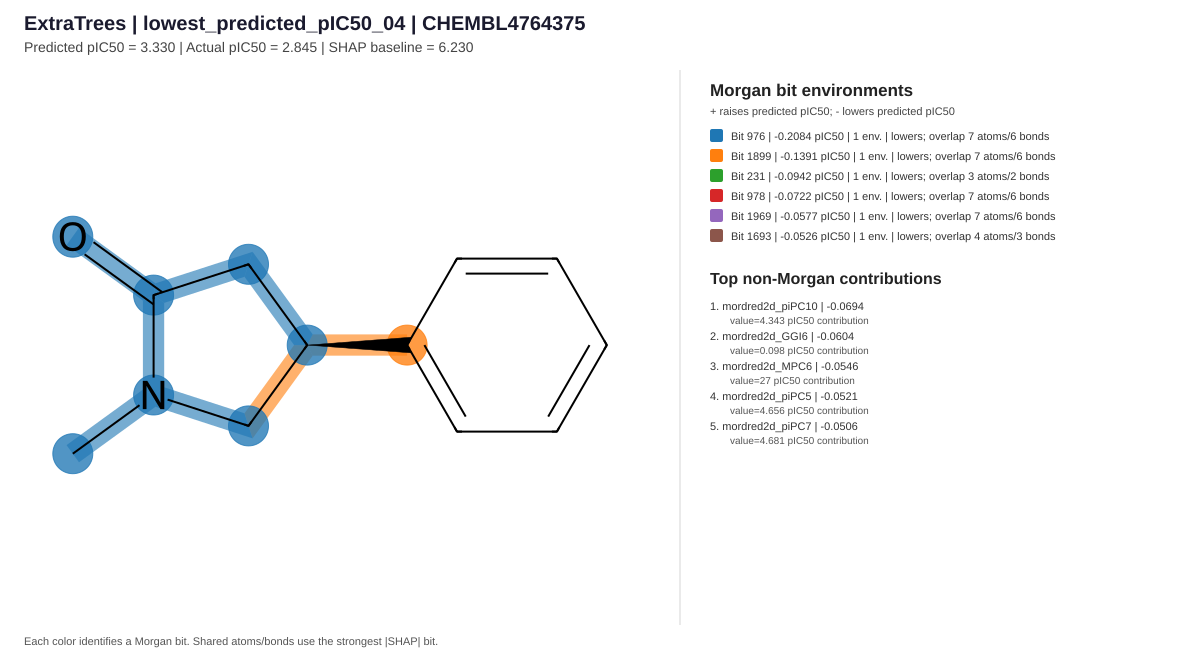

ExtraTreesRegressor | lowest 05/10 | rank 5/1283 | CHEMBL4792834 | predicted pIC50=3.360 | actual pIC50=3.186


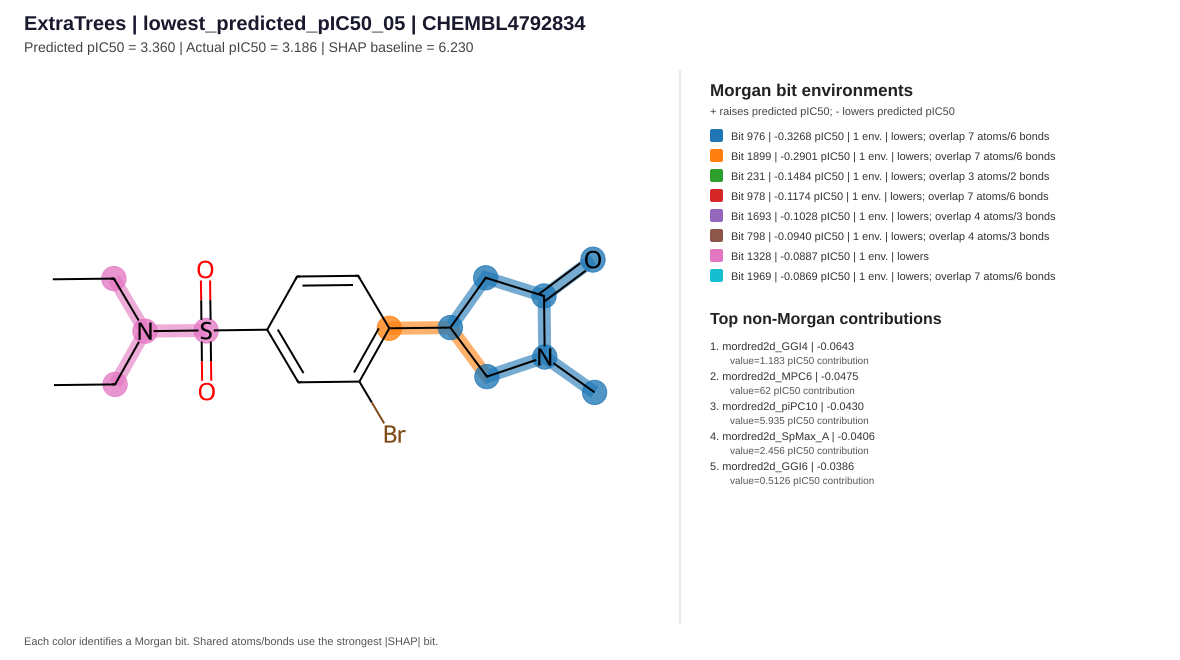

ExtraTreesRegressor | lowest 06/10 | rank 6/1283 | CHEMBL4751250 | predicted pIC50=3.488 | actual pIC50=3.602


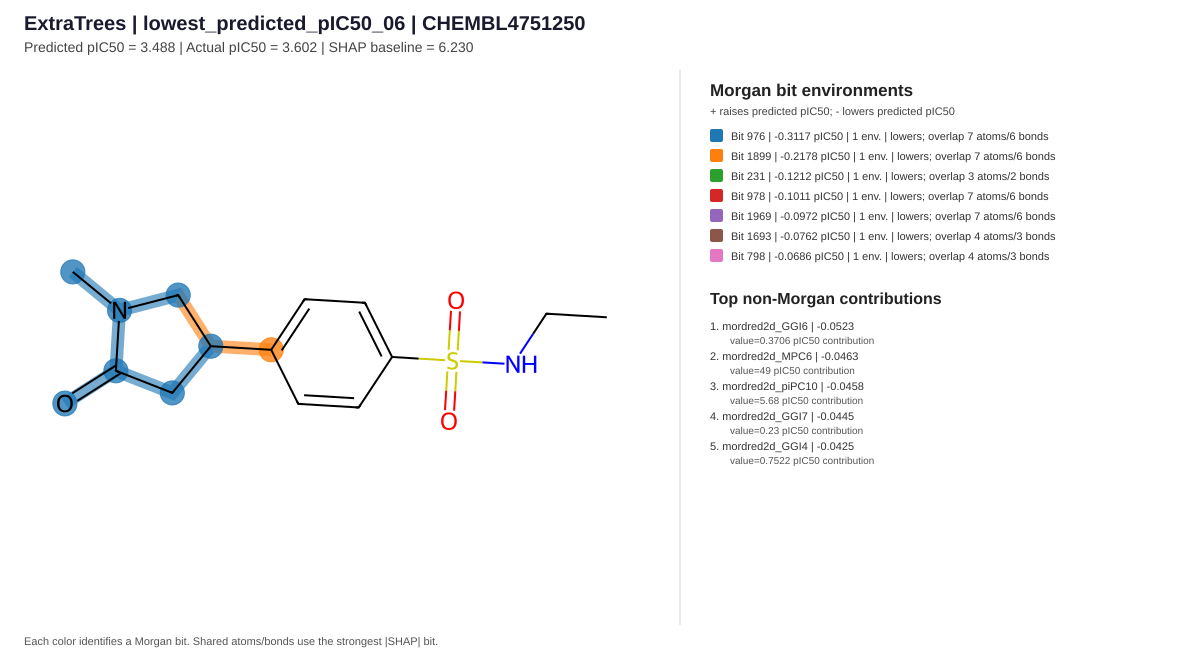

ExtraTreesRegressor | lowest 07/10 | rank 7/1283 | CHEMBL4742787 | predicted pIC50=3.491 | actual pIC50=3.833


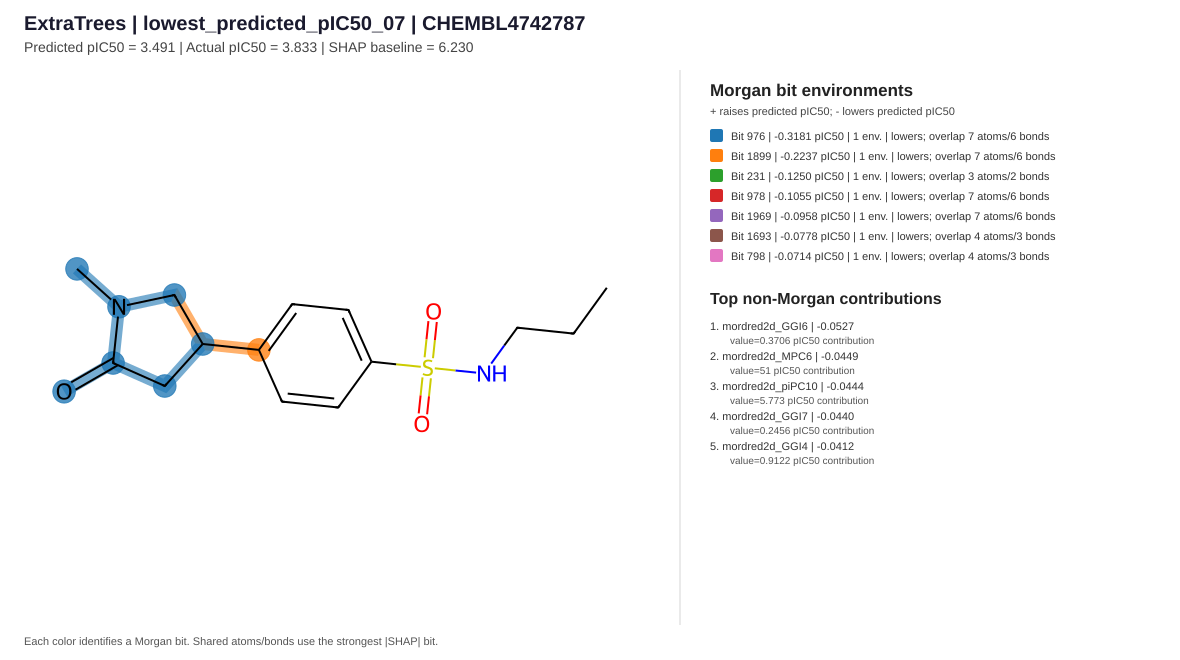

ExtraTreesRegressor | lowest 08/10 | rank 8/1283 | CHEMBL4791527 | predicted pIC50=3.507 | actual pIC50=3.910


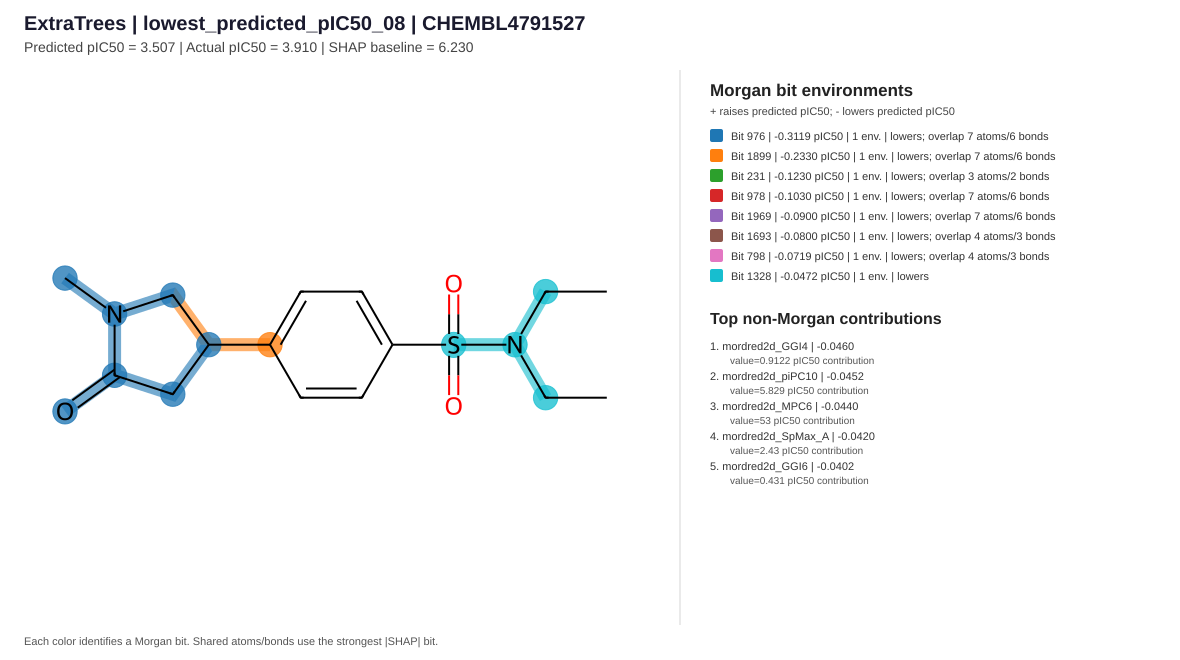

ExtraTreesRegressor | lowest 09/10 | rank 9/1283 | CHEMBL4747961 | predicted pIC50=3.519 | actual pIC50=3.873


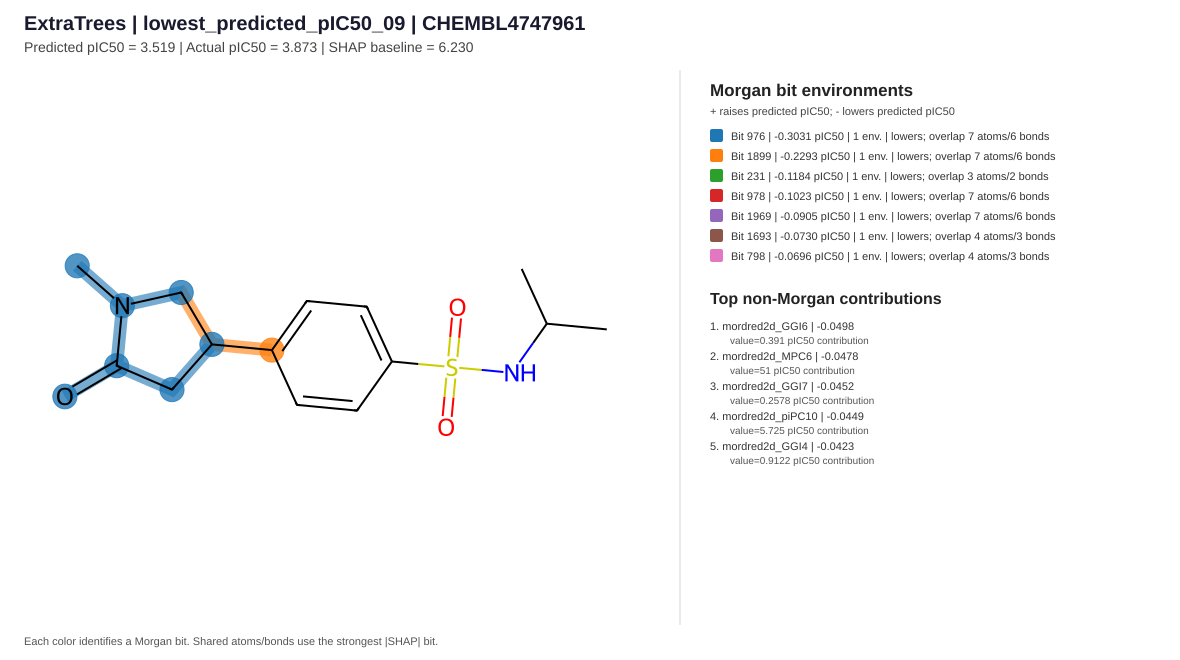

ExtraTreesRegressor | lowest 10/10 | rank 10/1283 | CHEMBL4789038 | predicted pIC50=3.676 | actual pIC50=3.380


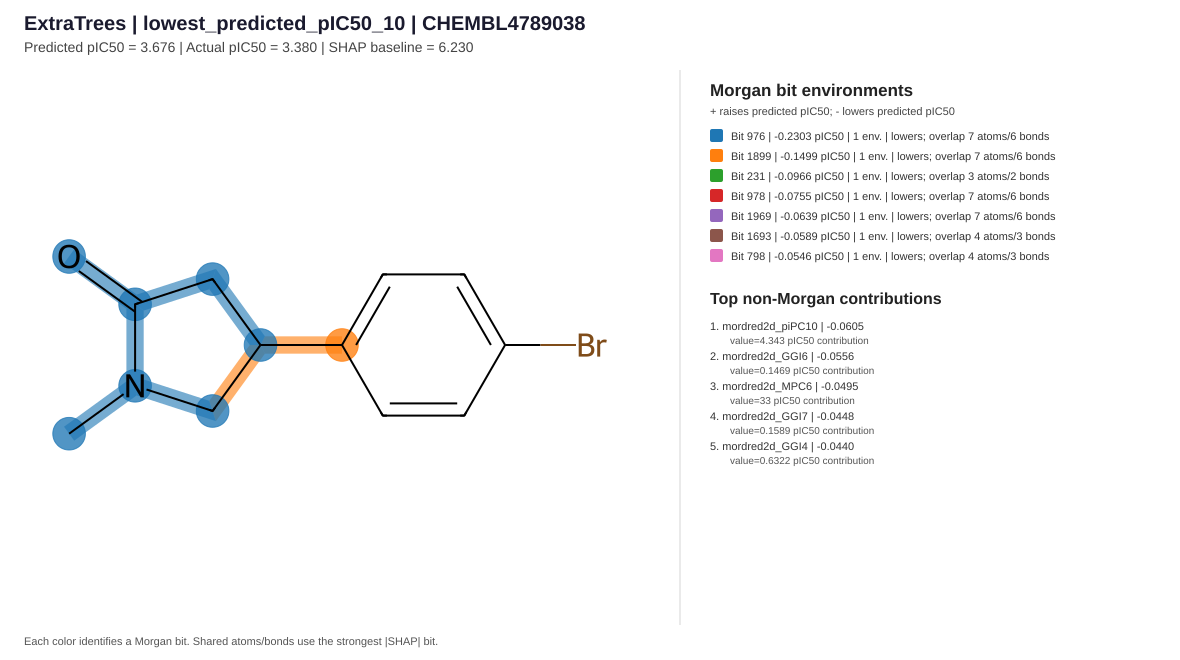

ExtraTreesRegressor | middle 01/10 | rank 637/1283 | CHEMBL5802415 | predicted pIC50=6.174 | actual pIC50=5.260


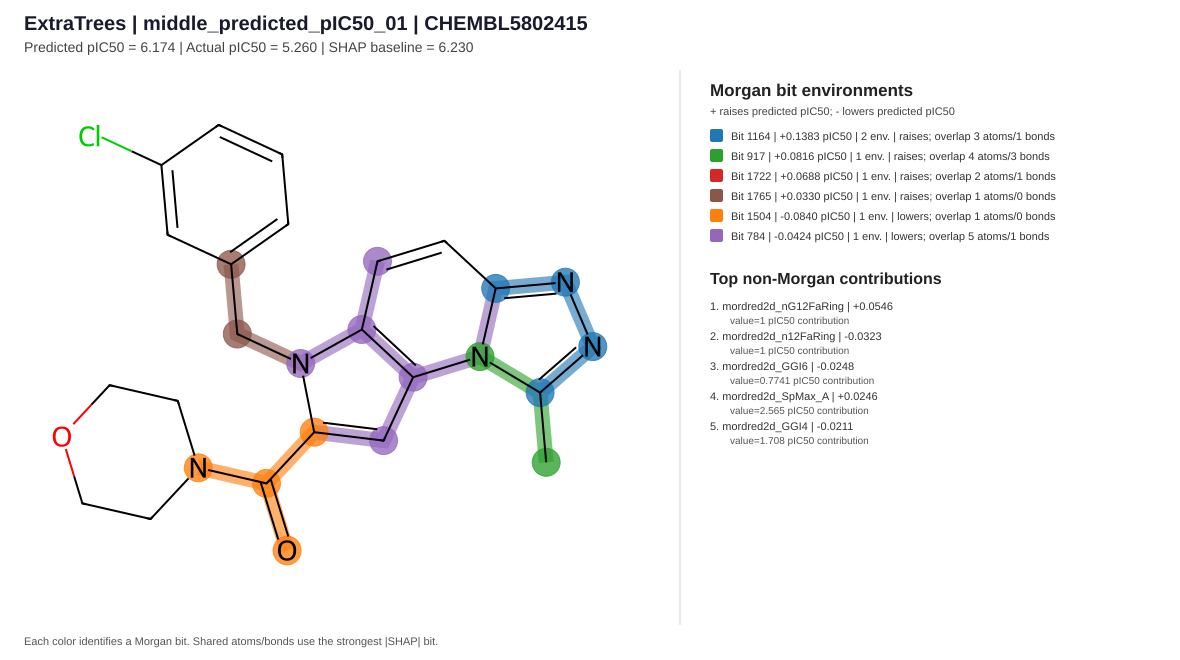

ExtraTreesRegressor | middle 02/10 | rank 638/1283 | CHEMBL4859907 | predicted pIC50=6.174 | actual pIC50=5.800


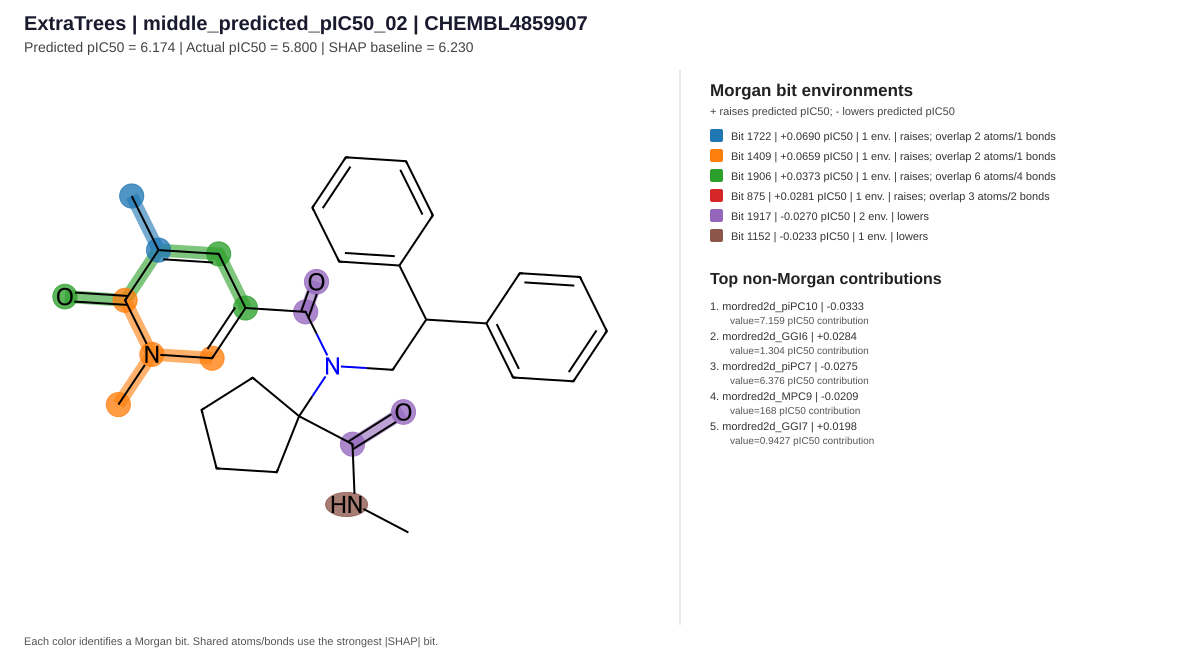

ExtraTreesRegressor | middle 03/10 | rank 639/1283 | CHEMBL4852030 | predicted pIC50=6.176 | actual pIC50=6.600


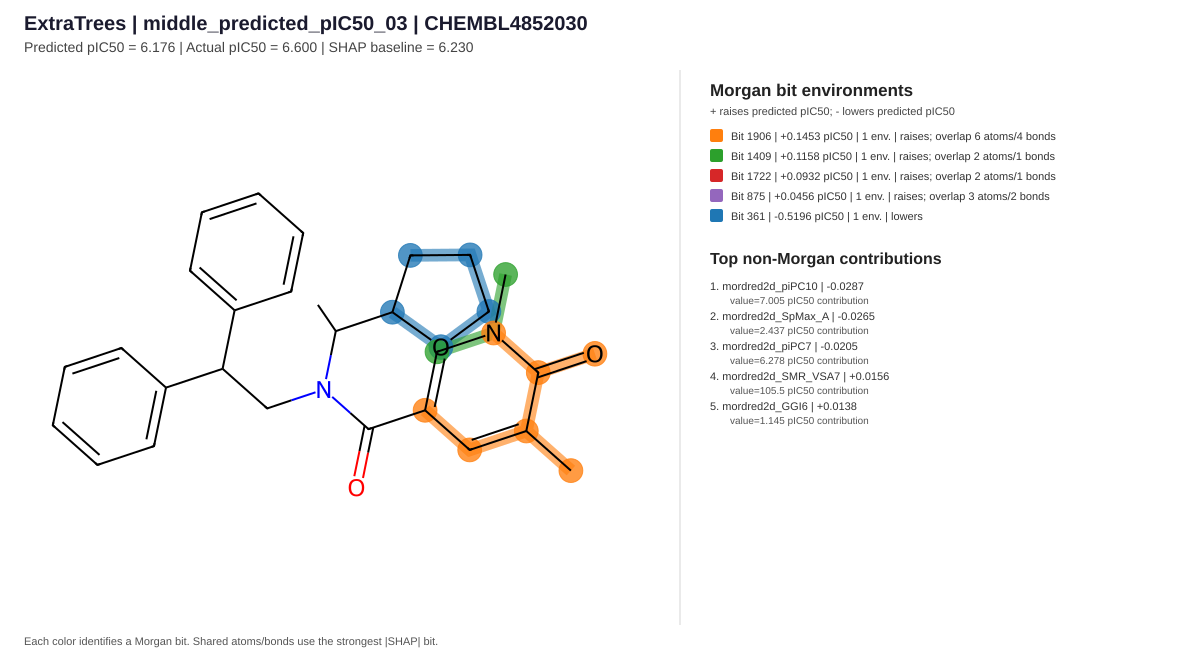

ExtraTreesRegressor | middle 04/10 | rank 640/1283 | CHEMBL3650871 | predicted pIC50=6.178 | actual pIC50=4.638


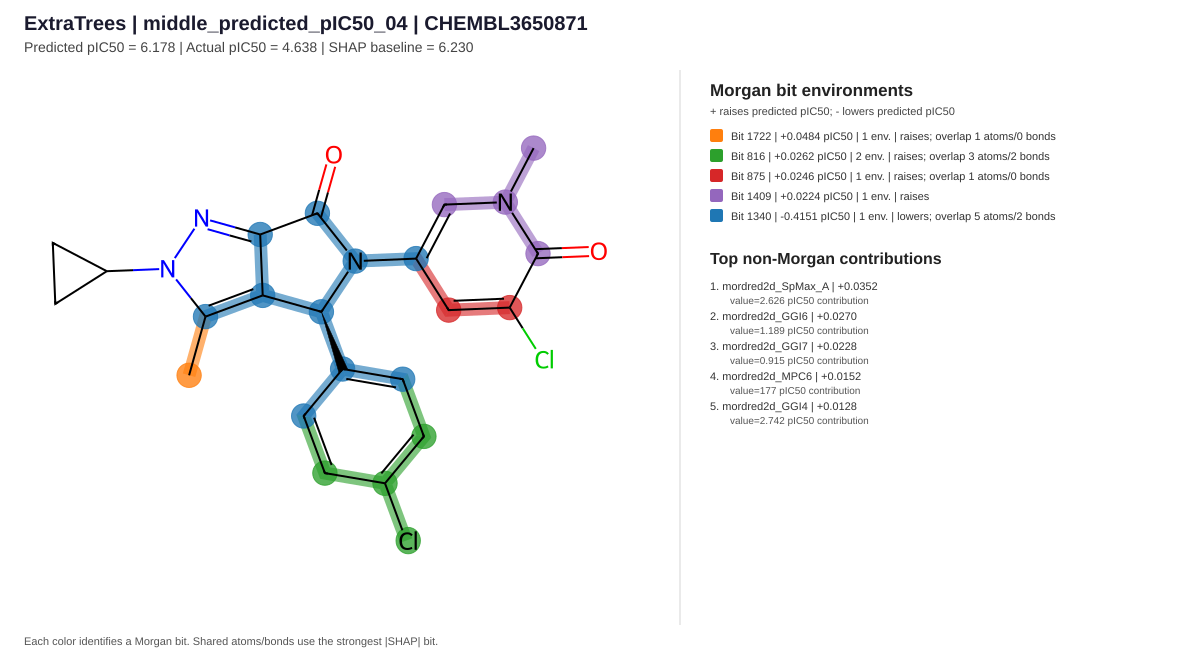

ExtraTreesRegressor | middle 05/10 | rank 641/1283 | CHEMBL5797222 | predicted pIC50=6.179 | actual pIC50=6.770


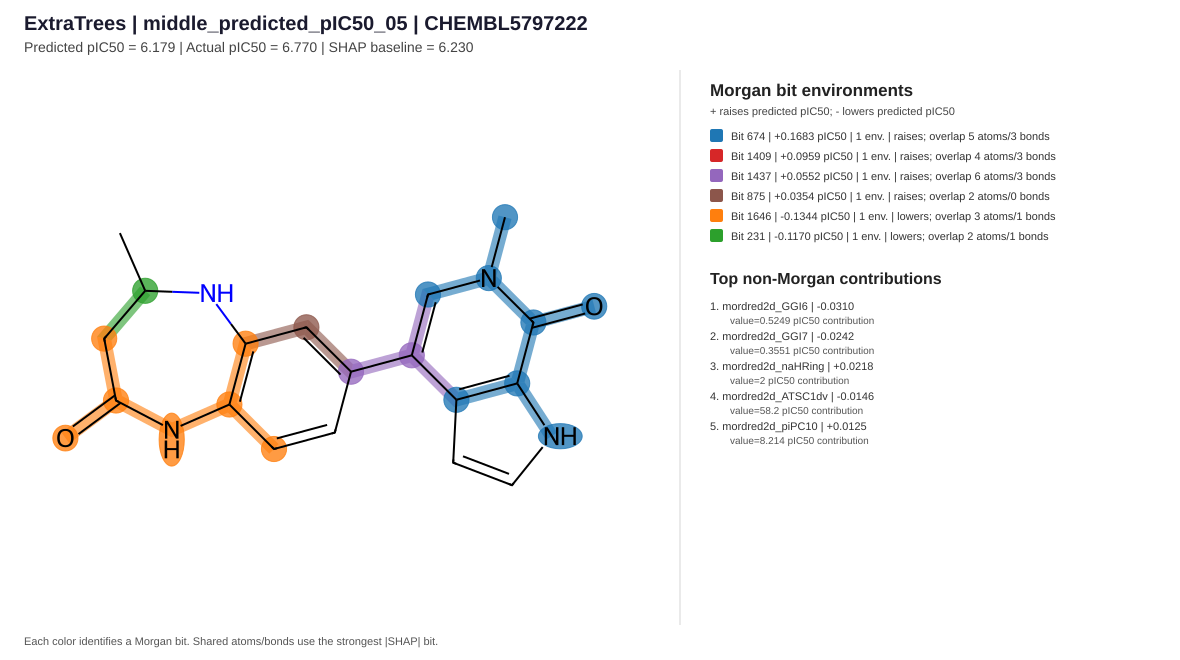

ExtraTreesRegressor | middle 06/10 | rank 642/1283 | CHEMBL6033164 | predicted pIC50=6.180 | actual pIC50=6.289


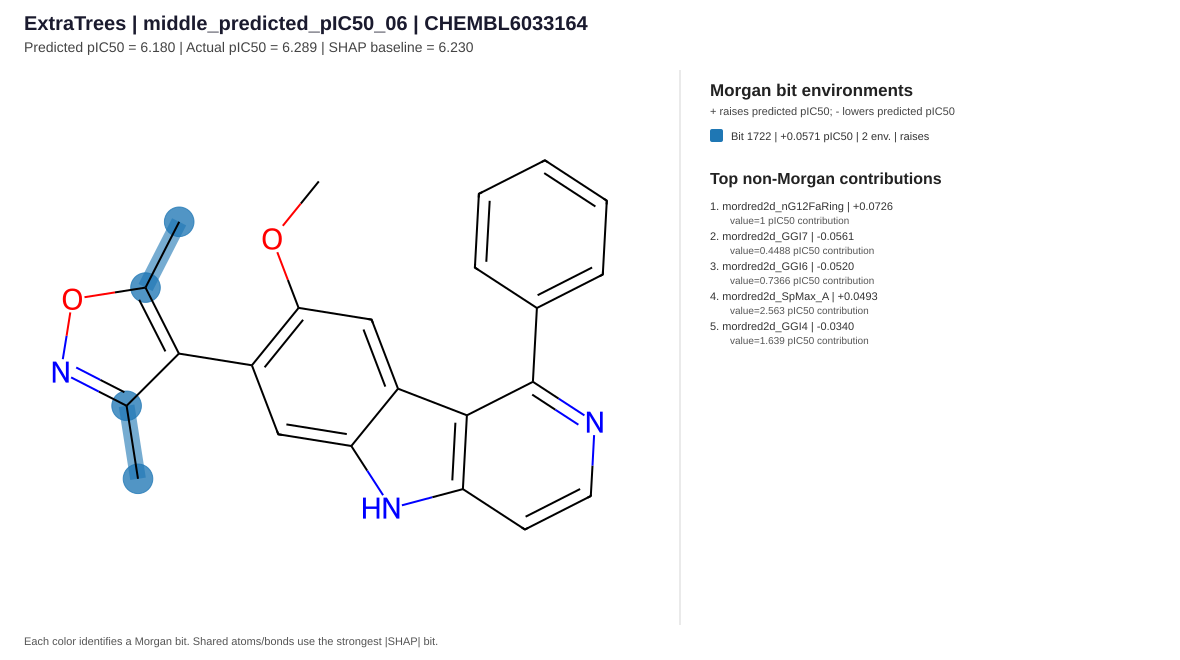

ExtraTreesRegressor | middle 07/10 | rank 643/1283 | CHEMBL5780342 | predicted pIC50=6.181 | actual pIC50=5.561


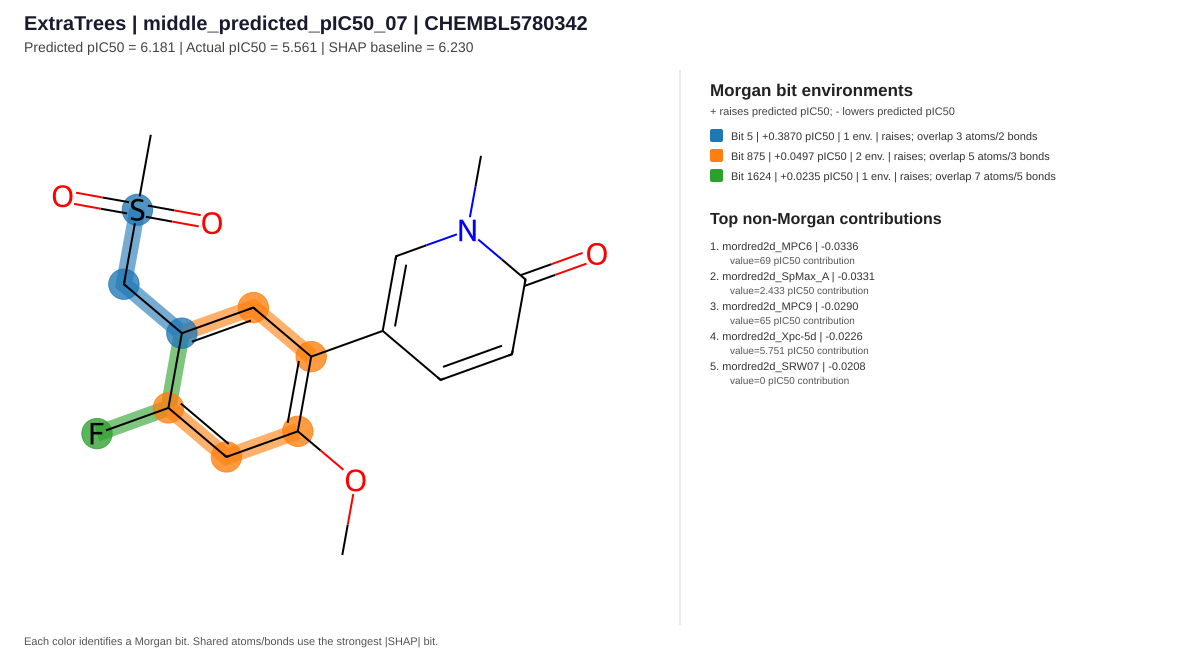

ExtraTreesRegressor | middle 08/10 | rank 644/1283 | CHEMBL6054534 | predicted pIC50=6.182 | actual pIC50=6.201


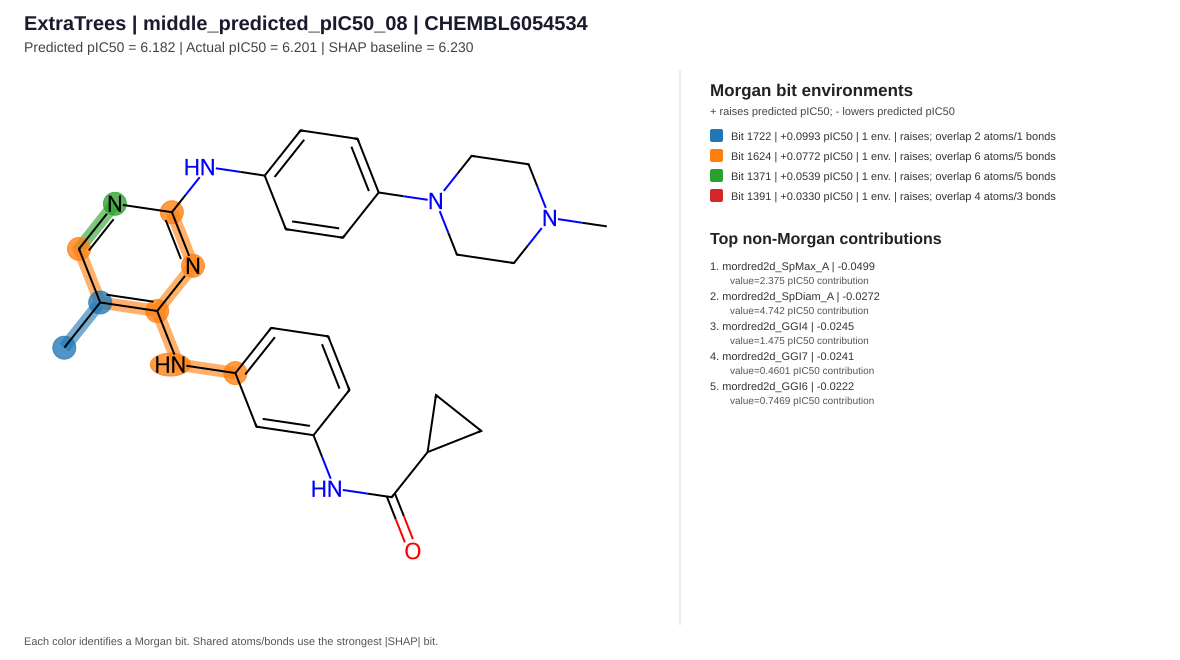

ExtraTreesRegressor | middle 09/10 | rank 645/1283 | CHEMBL3605566 | predicted pIC50=6.182 | actual pIC50=6.237


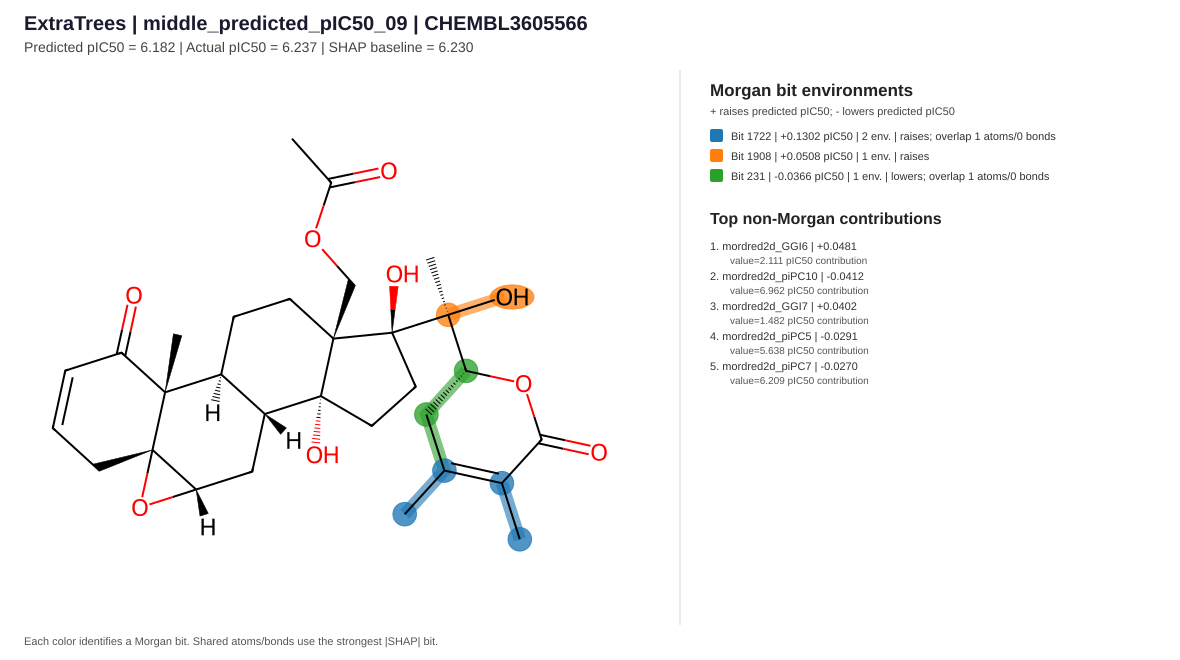

ExtraTreesRegressor | middle 10/10 | rank 646/1283 | CHEMBL5557599 | predicted pIC50=6.186 | actual pIC50=6.700


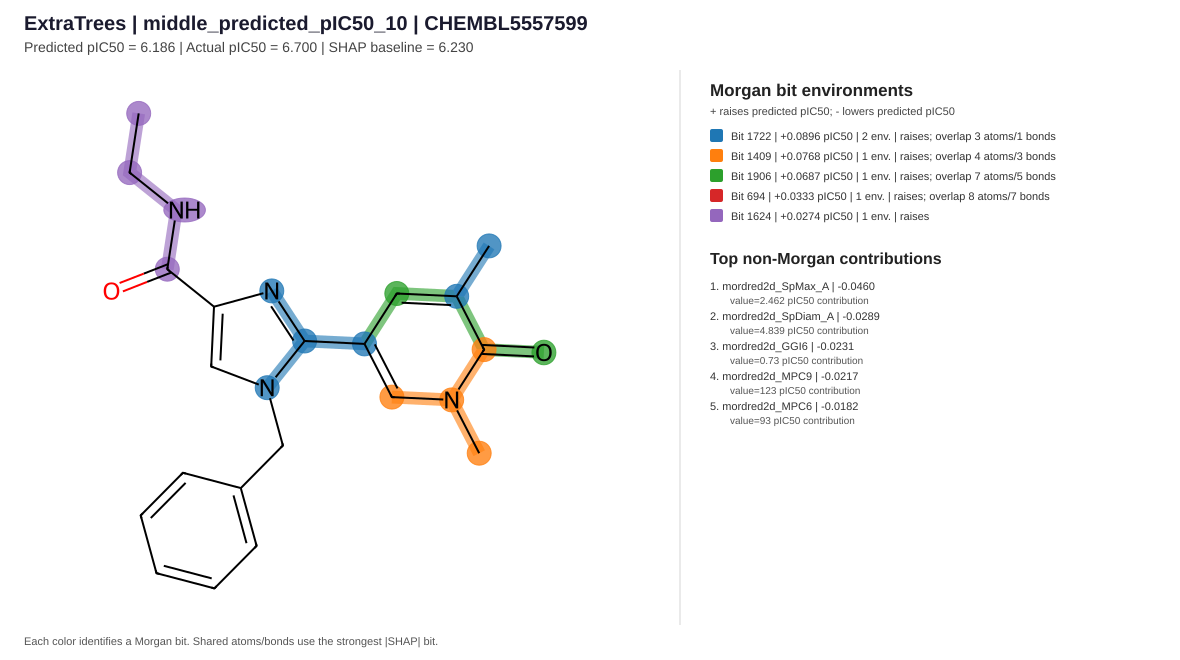

ExtraTreesRegressor | highest 01/10 | rank 1274/1283 | CHEMBL5200542 | predicted pIC50=8.811 | actual pIC50=9.237


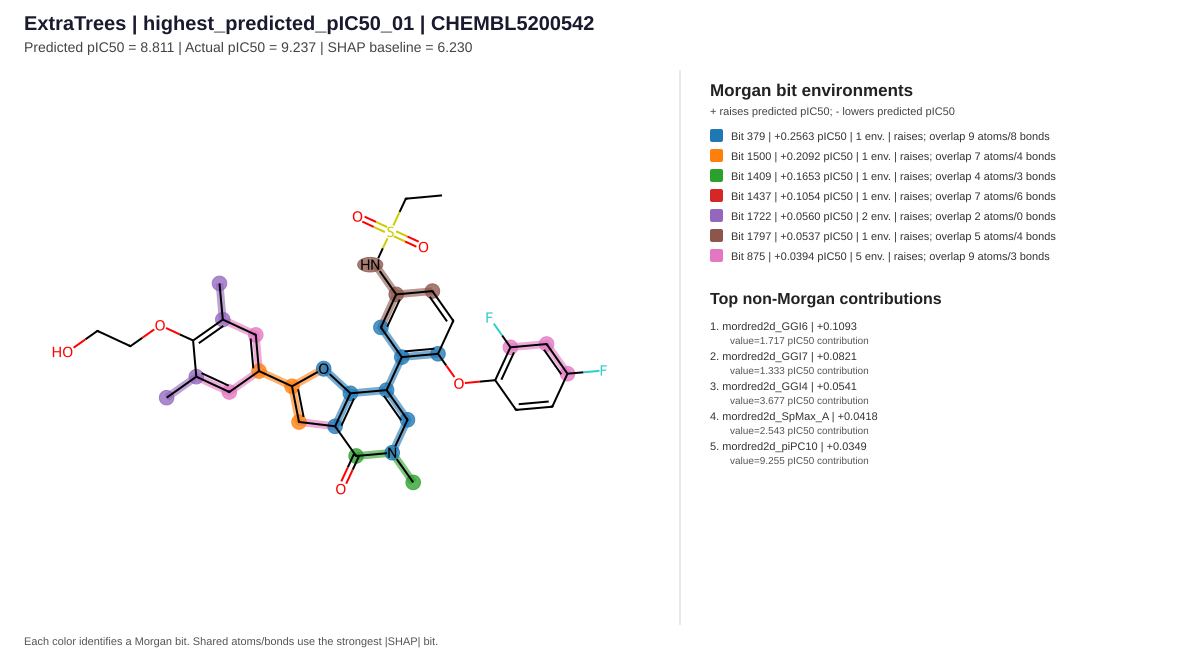

ExtraTreesRegressor | highest 02/10 | rank 1275/1283 | CHEMBL5171510 | predicted pIC50=8.825 | actual pIC50=9.264


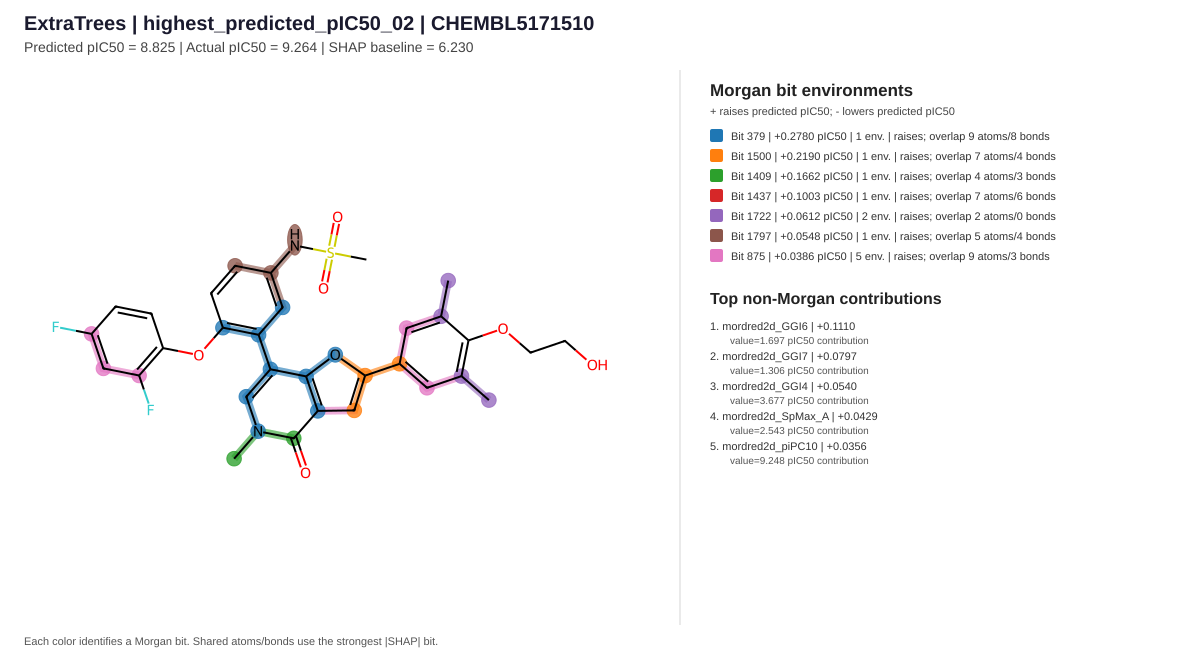

ExtraTreesRegressor | highest 03/10 | rank 1276/1283 | CHEMBL5184079 | predicted pIC50=8.826 | actual pIC50=9.230


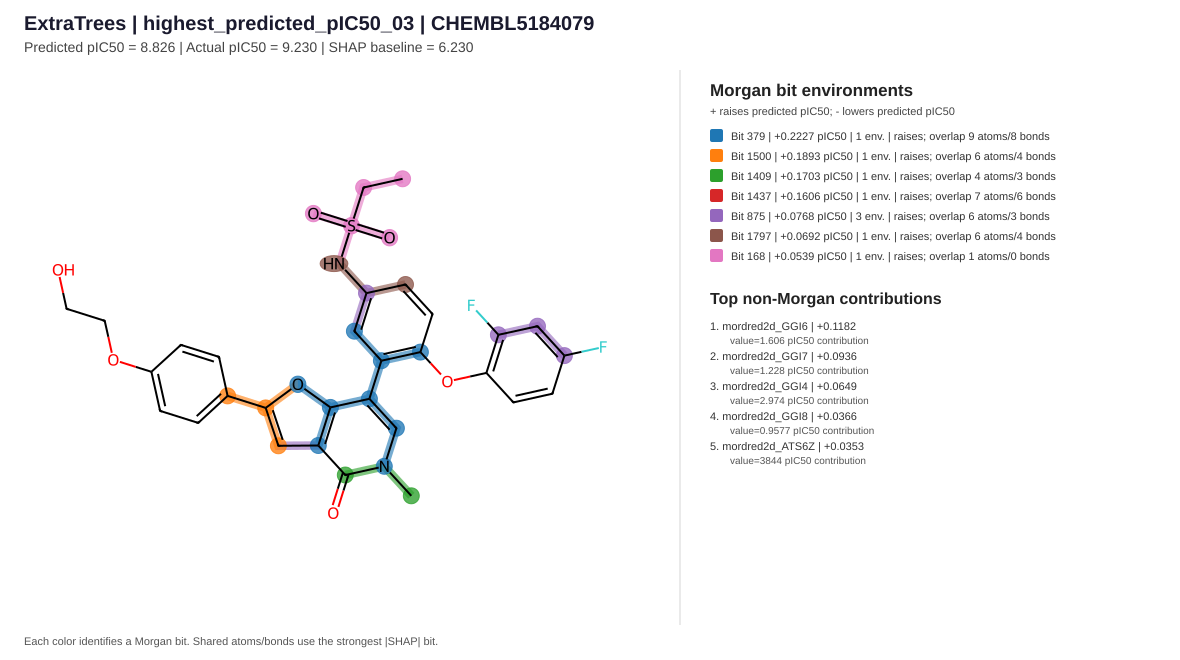

ExtraTreesRegressor | highest 04/10 | rank 1277/1283 | CHEMBL5883744 | predicted pIC50=8.830 | actual pIC50=8.796


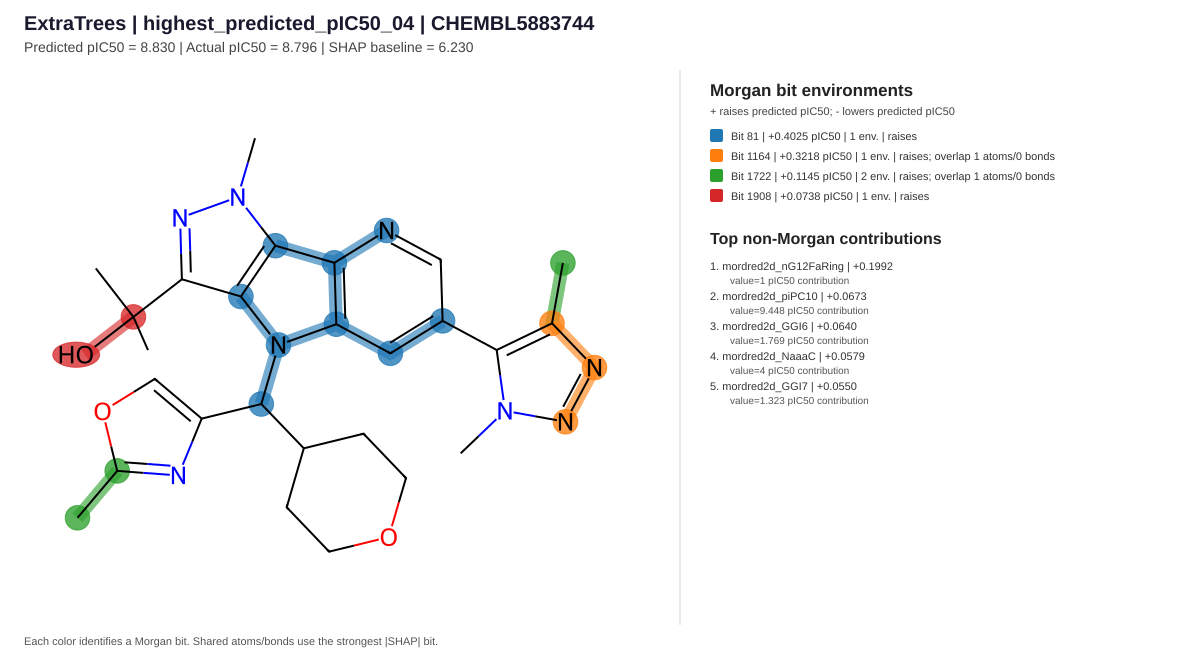

ExtraTreesRegressor | highest 05/10 | rank 1278/1283 | CHEMBL5173301 | predicted pIC50=8.858 | actual pIC50=8.863


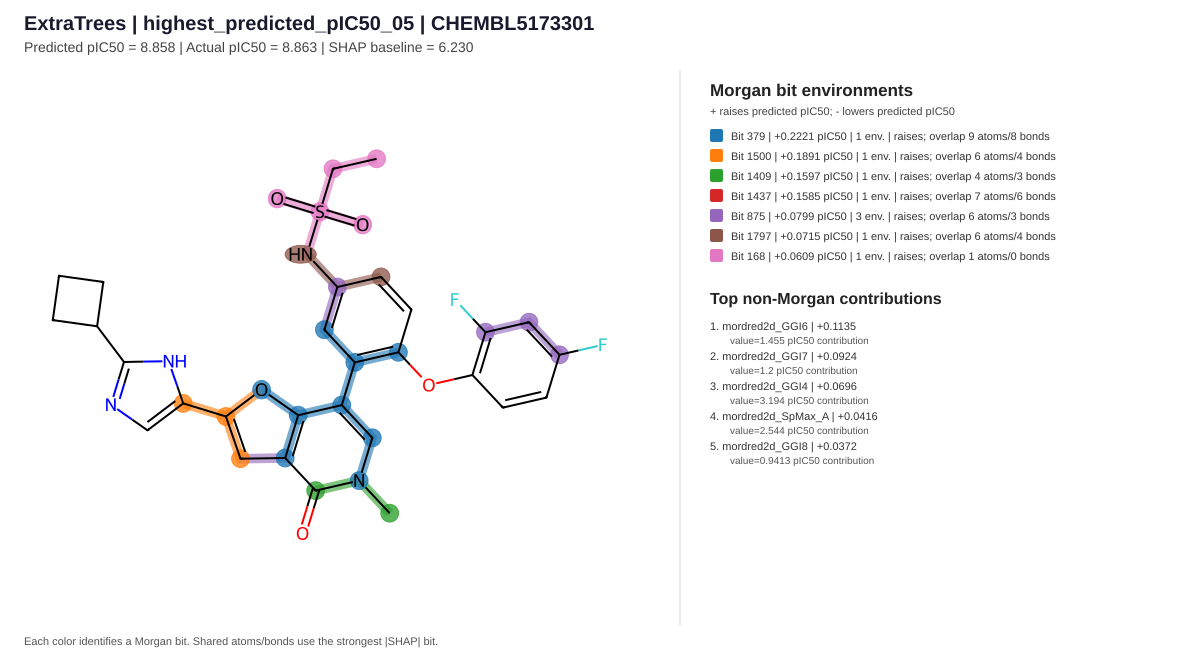

ExtraTreesRegressor | highest 06/10 | rank 1279/1283 | CHEMBL4850311 | predicted pIC50=8.910 | actual pIC50=7.569


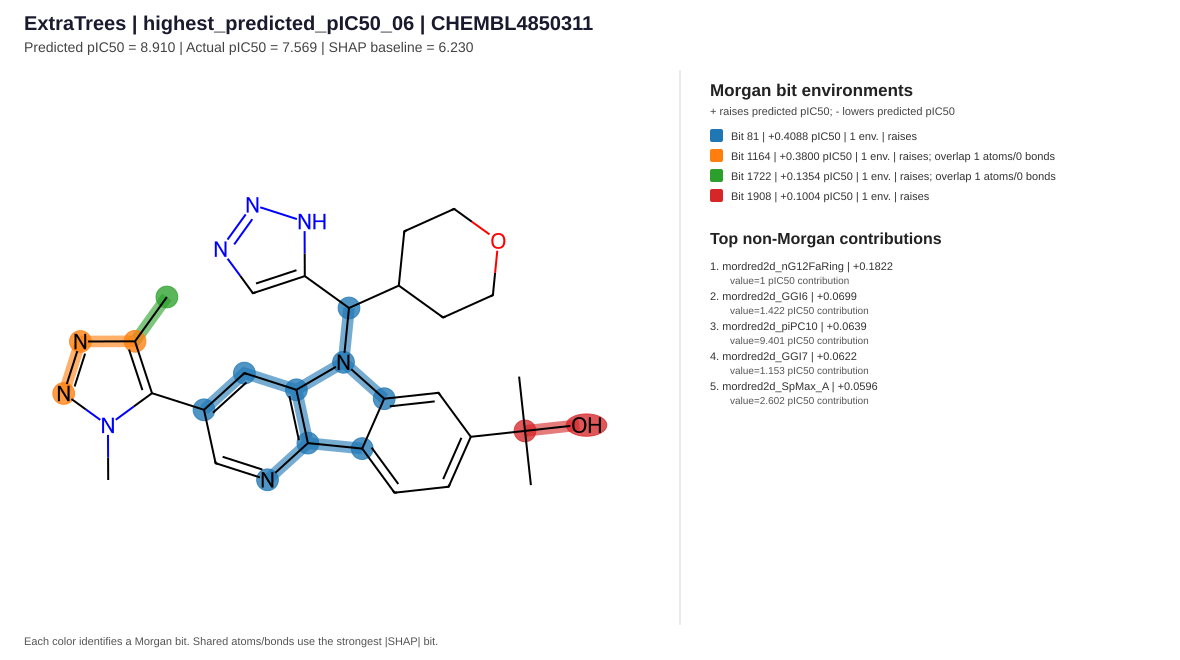

ExtraTreesRegressor | highest 07/10 | rank 1280/1283 | CHEMBL6021830 | predicted pIC50=8.980 | actual pIC50=9.180


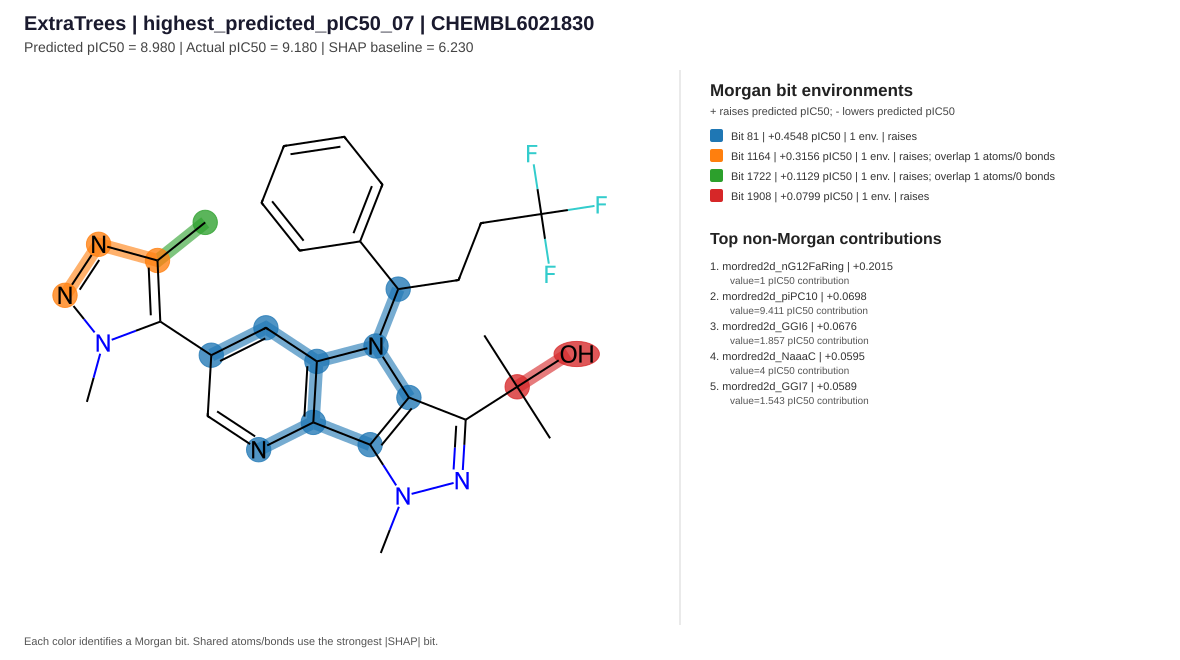

ExtraTreesRegressor | highest 08/10 | rank 1281/1283 | CHEMBL6051531 | predicted pIC50=9.028 | actual pIC50=9.310


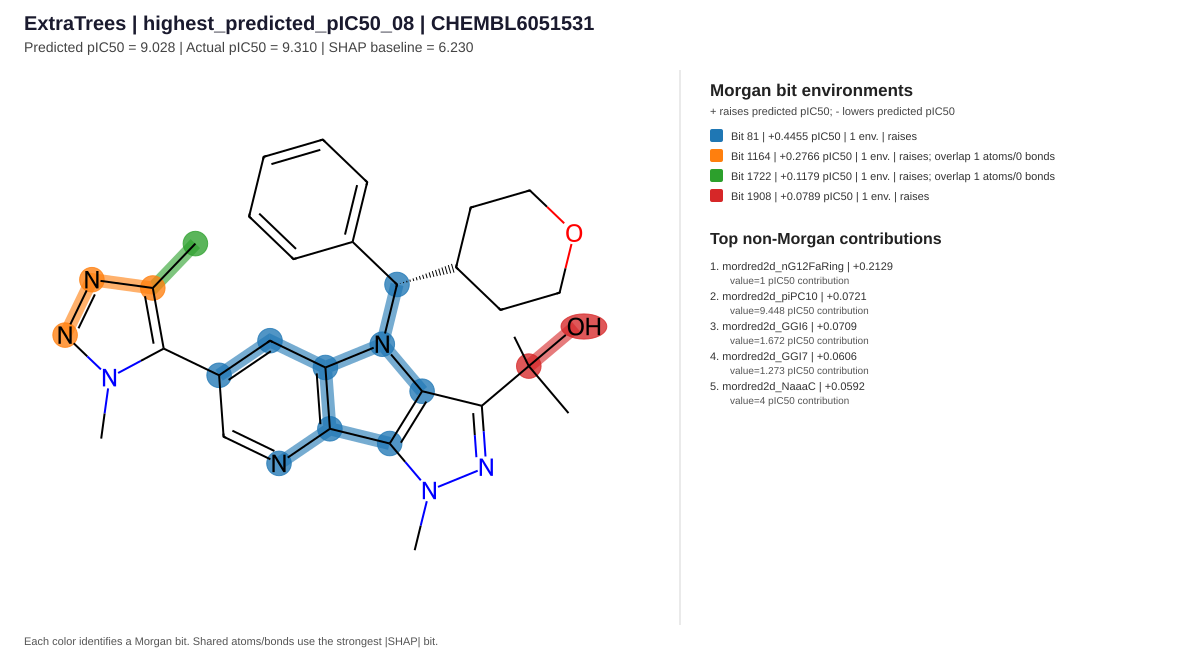

ExtraTreesRegressor | highest 09/10 | rank 1282/1283 | CHEMBL5816607 | predicted pIC50=9.103 | actual pIC50=8.721


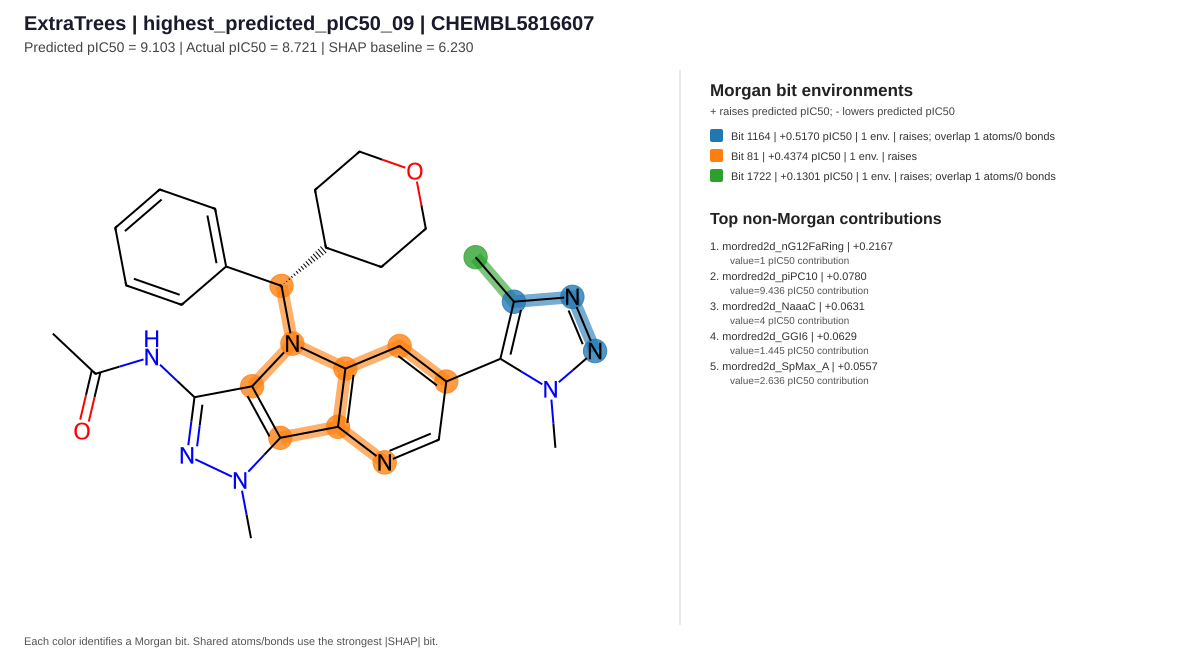

ExtraTreesRegressor | highest 10/10 | rank 1283/1283 | CHEMBL6010533 | predicted pIC50=9.273 | actual pIC50=8.337


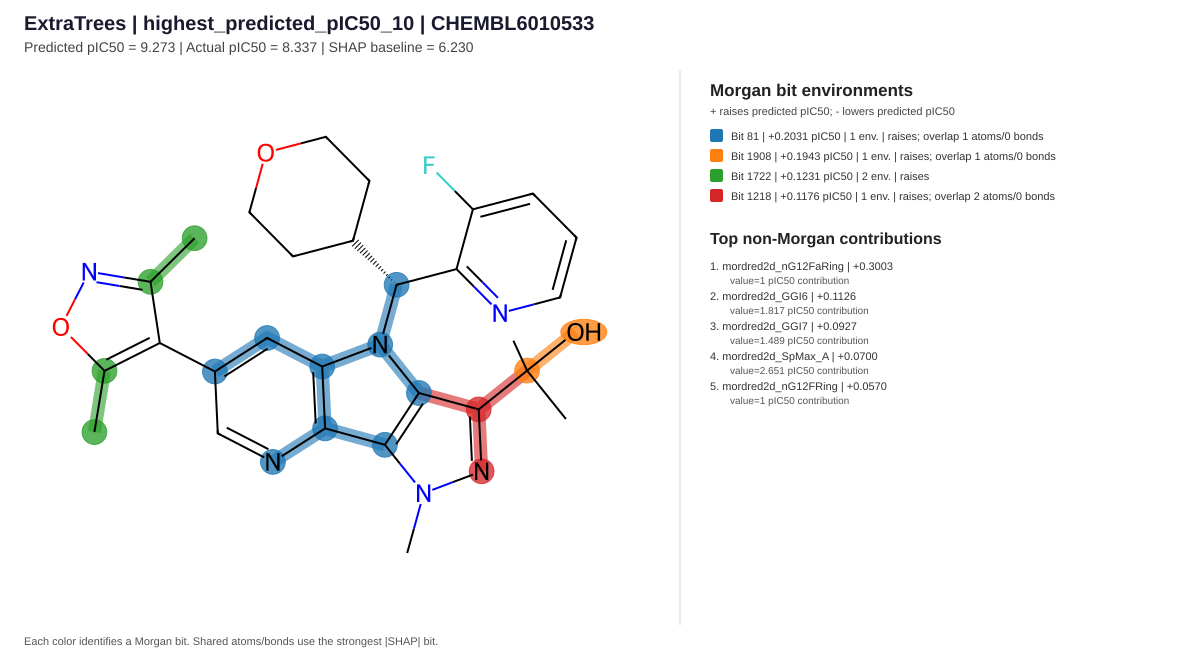

,model,group,case,rank_within_group,prediction_rank,chembl_id,predicted_pIC50,actual_pIC50,shap_baseline,top_n_features,n_morgan_bits_mapped,figure_svg,figure_png
0,ExtraTreesRegressor,lowest,lowest_predicted_pIC50_01,1,1,CHEMBL4763815,3.210712,3.353596,6.229567,12,7,C:\Users\USER\Documents\E\Code\outputs\10c_mol...,C:\Users\USER\Documents\E\Code\outputs\10c_mol...
1,ExtraTreesRegressor,lowest,lowest_predicted_pIC50_02,2,2,CHEMBL4759311,3.231659,3.325139,6.229567,12,7,C:\Users\USER\Documents\E\Code\outputs\10c_mol...,C:\Users\USER\Documents\E\Code\outputs\10c_mol...
2,ExtraTreesRegressor,lowest,lowest_predicted_pIC50_03,3,3,CHEMBL4788775,3.329511,2.943095,6.229567,12,6,C:\Users\USER\Documents\E\Code\outputs\10c_mol...,C:\Users\USER\Documents\E\Code\outputs\10c_mol...
3,ExtraTreesRegressor,lowest,lowest_predicted_pIC50_04,4,4,CHEMBL4764375,3.329511,2.844664,6.229567,12,6,C:\Users\USER\Documents\E\Code\outputs\10c_mol...,C:\Users\USER\Documents\E\Code\outputs\10c_mol...
4,ExtraTreesRegressor,lowest,lowest_predicted_pIC50_05,5,5,CHEMBL4792834,3.360000,3.185752,6.229567,12,8,C:\Users\USER\Documents\E\Code\outputs\10c_mol...,C:\Users\USER\Documents\E\Code\outputs\10c_mol...
5,ExtraTreesRegressor,lowest,lowest_predicted_pIC50_06,6,6,CHEMBL4751250,3.488187,3.602060,6.229567,12,7,C:\Users\USER\Documents\E\Code\outputs\10c_mol...,C:\Users\USER\Documents\E\Code\outputs\10c_mol...
6,ExtraTreesRegressor,lowest,lowest_predicted_pIC50_07,7,7,CHEMBL4742787,3.491378,3.832683,6.229567,12,7,C:\Users\USER\Documents\E\Code\outputs\10c_mol...,C:\Users\USER\Documents\E\Code\outputs\10c_mol...
7,ExtraTreesRegressor,lowest,lowest_predicted_pIC50_08,8,8,CHEMBL4791527,3.506934,3.910095,6.229567,12,8,C:\Users\USER\Documents\E\Code\outputs\10c_mol...,C:\Users\USER\Documents\E\Code\outputs\10c_mol...
8,ExtraTreesRegressor,lowest,lowest_predicted_pIC50_09,9,9,CHEMBL4747961,3.518601,3.872895,6.229567,12,7,C:\Users\USER\Documents\E\Code\outputs\10c_mol...,C:\Users\USER\Documents\E\Code\outputs\10c_mol...
9,ExtraTreesRegressor,lowest,lowest_predicted_pIC50_10,10,10,CHEMBL4789038,3.676065,3.379864,6.229567,12,7,C:\Users\USER\Documents\E\Code\outputs\10c_mol...,C:\Users\USER\Documents\E\Code\outputs\10c_mol...


Saved 30 SVG and 300-dpi PNG figures for ExtraTreesRegressor under C:\Users\USER\Documents\E\Code\outputs\10c_molecular_highlighting\figures
ExtraTrees: all 30 figures and tables saved. Review them before Cell 6.


In [20]:
# 5. Select and display 30 ExtraTrees molecular SHAP examples.
N_PER_GROUP = 10
GROUP_ORDER = ["lowest", "middle", "highest"]


def choose_cases(model_name, n_per_group=N_PER_GROUP):
    """Select low, median-centered, and high prediction groups without overlap."""
    frame = predictions.loc[predictions.model == model_name].copy()
    if (
        frame.chembl_id.duplicated().any()
        or set(frame.chembl_id) != set(test_ids.chembl_id)
    ):
        raise ValueError(
            f"Stage 08 prediction IDs do not match locked test IDs for {model_name}."
        )

    frame = frame.set_index("chembl_id").reindex(test_ids.chembl_id)
    if frame[["predicted_pIC50", "observed_pIC50"]].isna().any().any():
        raise ValueError(f"Missing predicted or actual pIC50 values for {model_name}.")
    if not np.isfinite(frame[["predicted_pIC50", "observed_pIC50"]].to_numpy(dtype=float)).all():
        raise ValueError(f"Non-finite predicted or actual pIC50 values for {model_name}.")

    # Sort on predictions only; observed/actual pIC50 is carried along for display.
    ordered = frame.sort_values("predicted_pIC50", kind="stable")
    n = len(ordered)
    if n < 3 * n_per_group:
        raise ValueError(
            f"Need at least {3 * n_per_group} test molecules to select "
            f"{n_per_group} per group; found {n}."
        )

    # Ten consecutive rows centered as closely as possible on the median rank.
    middle_start = max(0, min(n - n_per_group, n // 2 - n_per_group // 2))
    positions_by_group = {
        "lowest": list(range(n_per_group)),
        "middle": list(range(middle_start, middle_start + n_per_group)),
        "highest": list(range(n - n_per_group, n)),
    }

    rows = []
    for group in GROUP_ORDER:
        for rank_in_group, position in enumerate(positions_by_group[group], start=1):
            molecule = ordered.iloc[position]
            chembl_id = str(ordered.index[position])
            rows.append(
                {
                    "model": model_name,
                    "group": group,
                    "case": f"{group}_predicted_pIC50_{rank_in_group:02d}",
                    "rank_within_group": rank_in_group,
                    "prediction_rank": position + 1,
                    "chembl_id": chembl_id,
                    "predicted_pIC50": float(molecule["predicted_pIC50"]),
                    "actual_pIC50": float(molecule["observed_pIC50"]),
                }
            )

    cases = pd.DataFrame(rows)
    if cases.chembl_id.duplicated().any():
        raise ValueError(
            f"Prediction groups overlap for {model_name}; check test-set size."
        )
    if len(cases) != 3 * n_per_group:
        raise RuntimeError(f"Expected 30 cases for {model_name}; got {len(cases)}.")
    return cases


def render_model_cases(model_name):
    shap_frame = shap_by_model[model_name]
    feature_frame = X_test_fixed250
    case_table = choose_cases(model_name)
    case_records, feature_records, env_records = [], [], []

    print(
        f"Rendering {len(case_table)} {model_name} examples: "
        "10 lowest, 10 median-centered, and 10 highest predictions."
    )

    for case in case_table.itertuples(index=False):
        smiles = smiles_by_id.loc[case.chembl_id]
        mol = Chem.MolFromSmiles(smiles)
        if mol is None:
            print(f"Skipping invalid SMILES for {case.chembl_id}")
            continue

        shap_row = shap_frame.loc[case.chembl_id]
        raw_row = feature_frame.loc[case.chembl_id].reindex(shap_row.index)
        local_rows = pd.DataFrame(
            {
                "feature": shap_row.index.astype(str),
                "feature_value": raw_row.to_numpy(dtype=float),
                "shap_value": shap_row.to_numpy(dtype=float),
            }
        )
        local_rows["abs_shap"] = local_rows.shap_value.abs()

        # Additivity was checked in Stage 10A. Recover its baseline from the
        # saved model prediction and the complete saved feature contribution row.
        shap_values_sum = float(shap_row.sum())
        baseline = float(case.predicted_pIC50 - shap_values_sum)
        svg_text, png_image, top_entries, mapped_bits, descriptors = draw_shap_molecule(
            mol,
            model_name,
            case.case,
            case.chembl_id,
            case.predicted_pIC50,
            case.actual_pIC50,
            baseline,
            shap_row,
            local_rows,
        )

        stem = (
            f"molecular_SHAP_{safe_stem(model_name)}_"
            f"{safe_stem(case.case)}_{safe_stem(case.chembl_id)}"
        )
        svg_path = FIGURE_DIR / f"{stem}.svg"
        png_path = FIGURE_DIR / f"{stem}.png"
        svg_path.write_text(svg_text, encoding="utf-8")
        png_image.save(png_path, dpi=(300, 300))

        case_records.append(
            {
                "model": model_name,
                "group": case.group,
                "case": case.case,
                "rank_within_group": case.rank_within_group,
                "prediction_rank": case.prediction_rank,
                "chembl_id": case.chembl_id,
                "predicted_pIC50": case.predicted_pIC50,
                "actual_pIC50": case.actual_pIC50,
                "shap_baseline": baseline,
                "top_n_features": TOP_N,
                "n_morgan_bits_mapped": len(mapped_bits),
                "figure_svg": str(svg_path),
                "figure_png": str(png_path),
            }
        )

        for rank, (feature, value, raw) in enumerate(top_entries, start=1):
            feature_records.append(
                {
                    "model": model_name,
                    "group": case.group,
                    "case": case.case,
                    "chembl_id": case.chembl_id,
                    "rank_abs_shap": rank,
                    "feature": feature,
                    "feature_value": raw,
                    "shap_value_pIC50": value,
                }
            )

        for (
            feature,
            bit,
            value,
            raw,
            atoms,
            bonds,
            n_occurrences,
            color_hex,
            overlap_atoms,
            overlap_bonds,
        ) in mapped_bits:
            env_records.append(
                {
                    "model": model_name,
                    "group": case.group,
                    "case": case.case,
                    "chembl_id": case.chembl_id,
                    "feature": feature,
                    "morgan_bit": bit,
                    "feature_value": raw,
                    "shap_value_pIC50": value,
                    "color_hex": color_hex,
                    "n_environments": n_occurrences,
                    "overlapping_atoms": overlap_atoms,
                    "overlapping_bonds": overlap_bonds,
                    "atom_indices": ",".join(map(str, sorted(atoms))),
                    "bond_indices": ",".join(map(str, sorted(bonds))),
                }
            )

        print(
            f"{model_name} | {case.group} {case.rank_within_group:02d}/10 | "
            f"rank {case.prediction_rank}/{len(test_ids)} | {case.chembl_id} | "
            f"predicted pIC50={case.predicted_pIC50:.3f} | "
            f"actual pIC50={case.actual_pIC50:.3f}"
        )
        display(SVG(data=svg_text))

    case_df = pd.DataFrame(case_records)
    features_df = pd.DataFrame(feature_records)
    env_df = pd.DataFrame(env_records)

    if len(case_df) != 3 * N_PER_GROUP:
        raise RuntimeError(
            f"Rendered {len(case_df)} of {3 * N_PER_GROUP} requested "
            f"{model_name} examples. Check invalid or missing structures."
        )

    model_short = model_name.replace("Regressor", "")
    case_df.to_csv(TABLE_DIR / f"molecular_SHAP_cases_{model_short}.csv", index=False)
    features_df.to_csv(
        TABLE_DIR / f"molecular_SHAP_top_features_{model_short}.csv",
        index=False,
    )
    env_df.to_csv(
        TABLE_DIR / f"molecular_SHAP_mapped_environments_{model_short}.csv",
        index=False,
    )

    display(case_df)
    print(
        f"Saved {len(case_df)} SVG and 300-dpi PNG figures for "
        f"{model_name} under {FIGURE_DIR}"
    )
    return case_df, features_df, env_df


et_cases, et_top_features, et_environments = render_model_cases(
    "ExtraTreesRegressor"
)
print("ExtraTrees: all 30 figures and tables saved. Review them before Cell 6.")


Rendering 30 CatBoostRegressor examples: 10 lowest, 10 median-centered, and 10 highest predictions.
CatBoostRegressor | lowest 01/10 | rank 1/1283 | CHEMBL4748673 | predicted pIC50=2.993 | actual pIC50=3.493


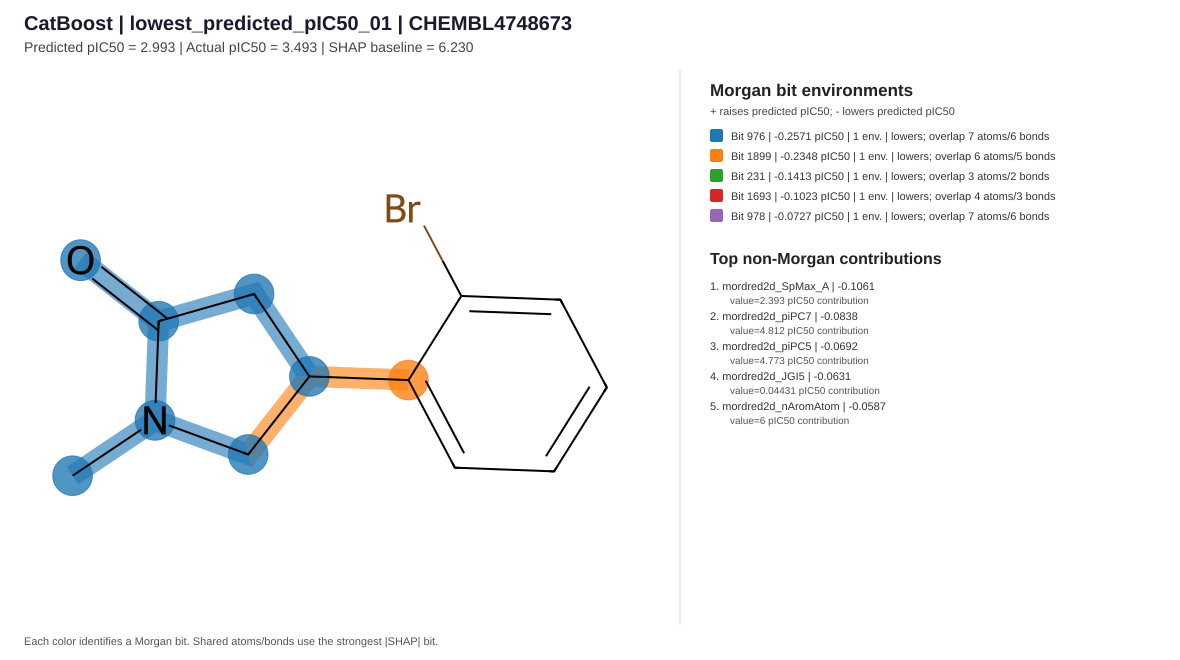

CatBoostRegressor | lowest 02/10 | rank 2/1283 | CHEMBL4788775 | predicted pIC50=3.032 | actual pIC50=2.943


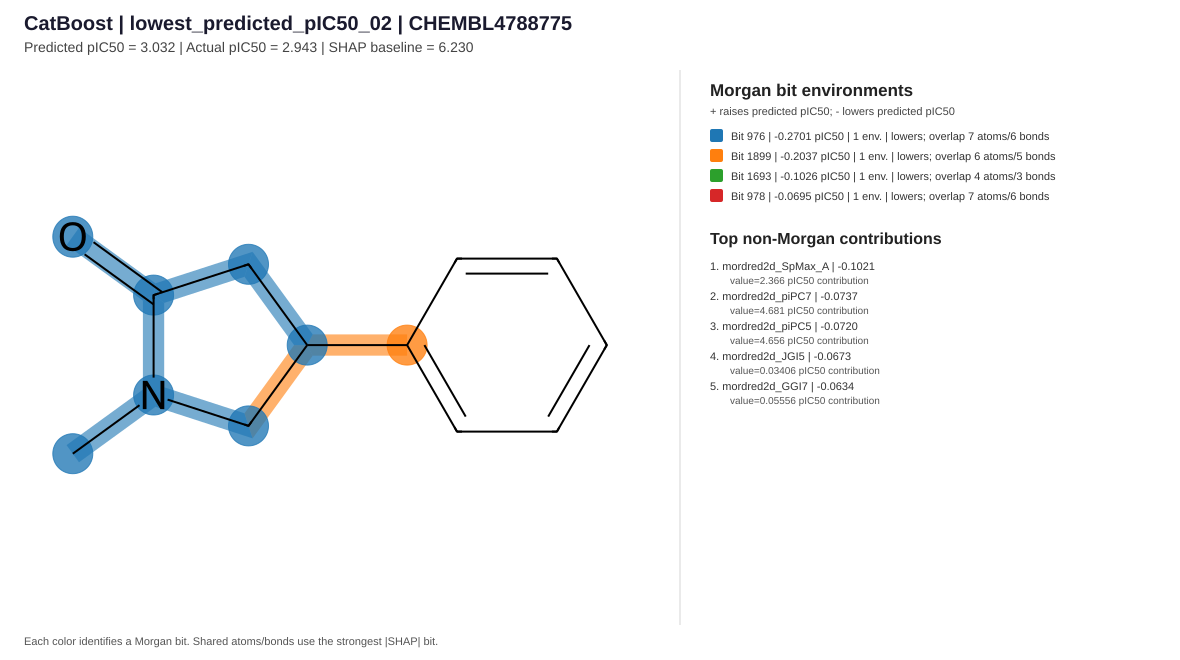

CatBoostRegressor | lowest 03/10 | rank 3/1283 | CHEMBL4764375 | predicted pIC50=3.032 | actual pIC50=2.845


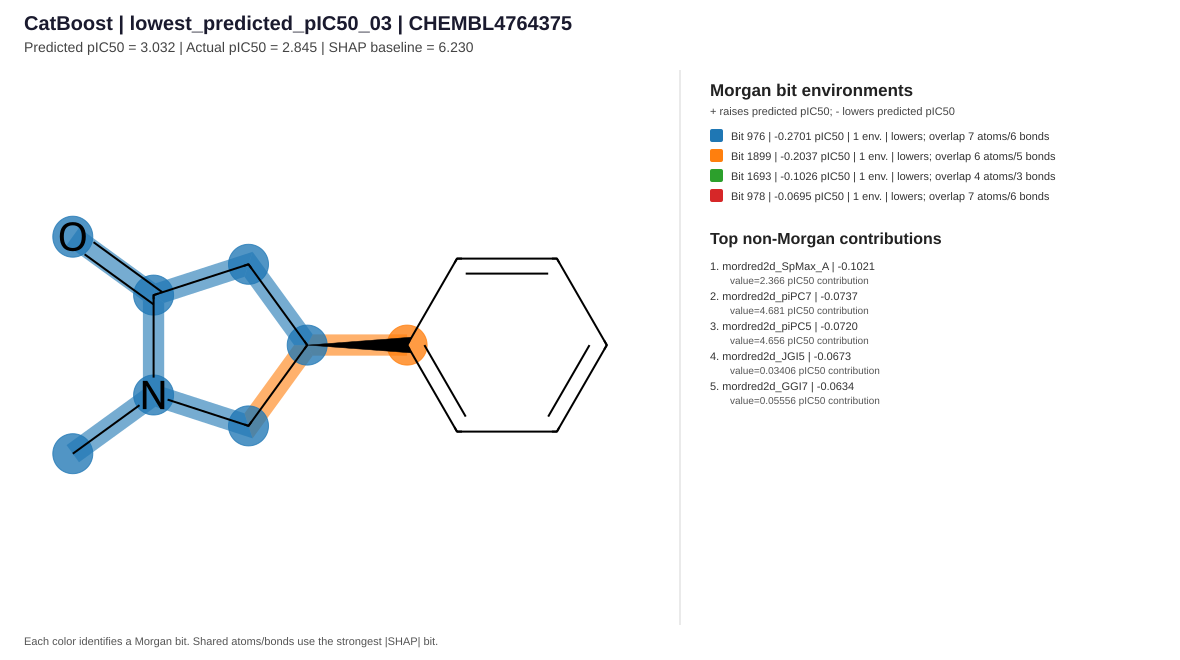

CatBoostRegressor | lowest 04/10 | rank 4/1283 | CHEMBL4792834 | predicted pIC50=3.102 | actual pIC50=3.186


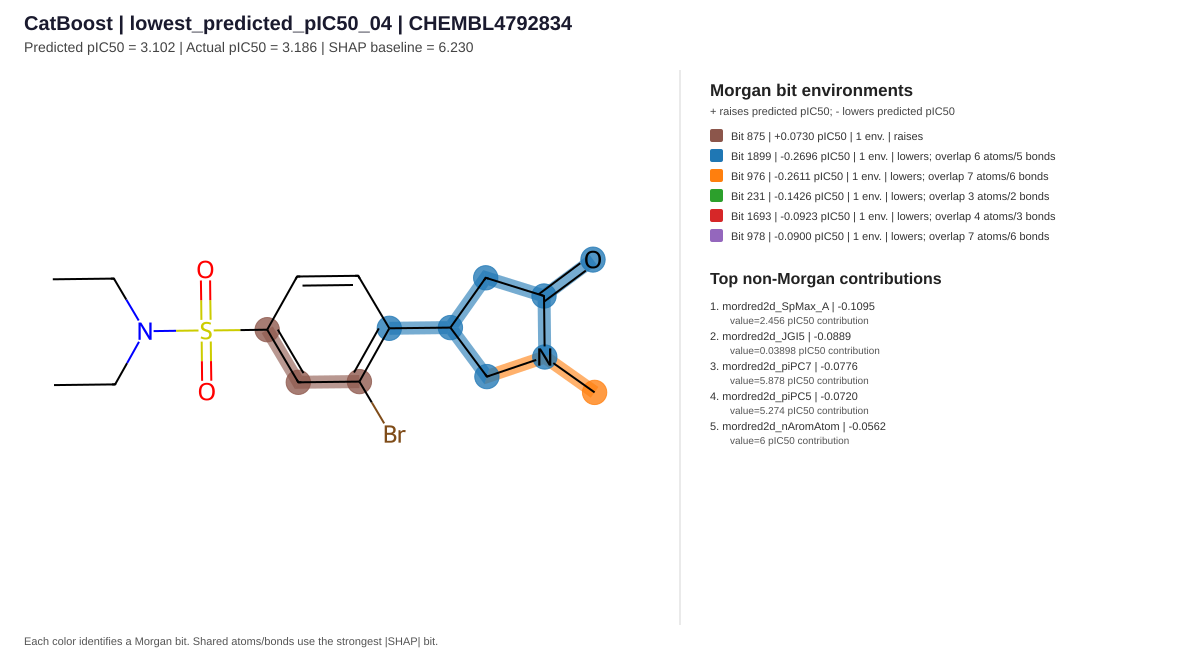

CatBoostRegressor | lowest 05/10 | rank 5/1283 | CHEMBL4751250 | predicted pIC50=3.119 | actual pIC50=3.602


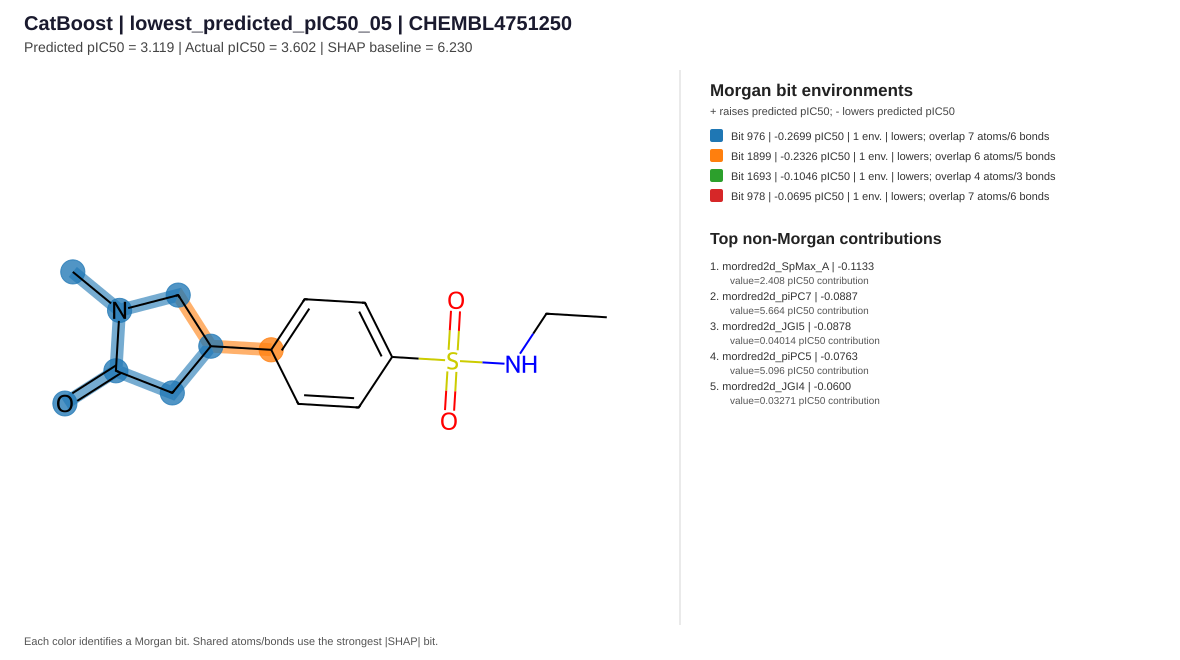

CatBoostRegressor | lowest 06/10 | rank 6/1283 | CHEMBL4747961 | predicted pIC50=3.192 | actual pIC50=3.873


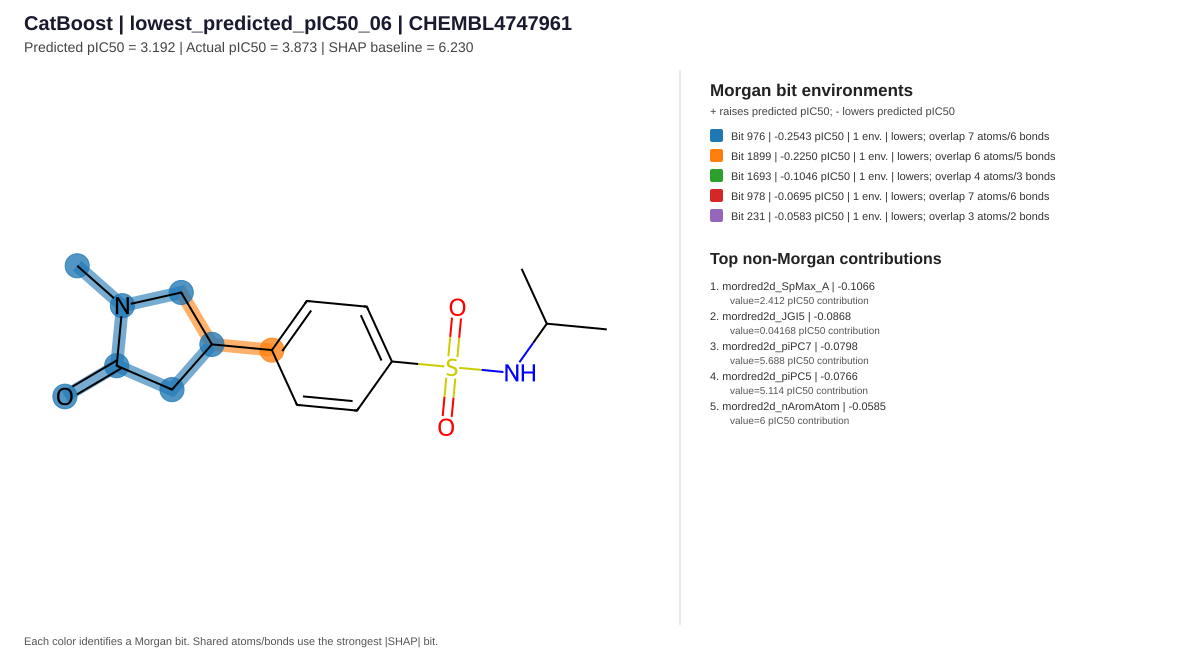

CatBoostRegressor | lowest 07/10 | rank 7/1283 | CHEMBL4789038 | predicted pIC50=3.213 | actual pIC50=3.380


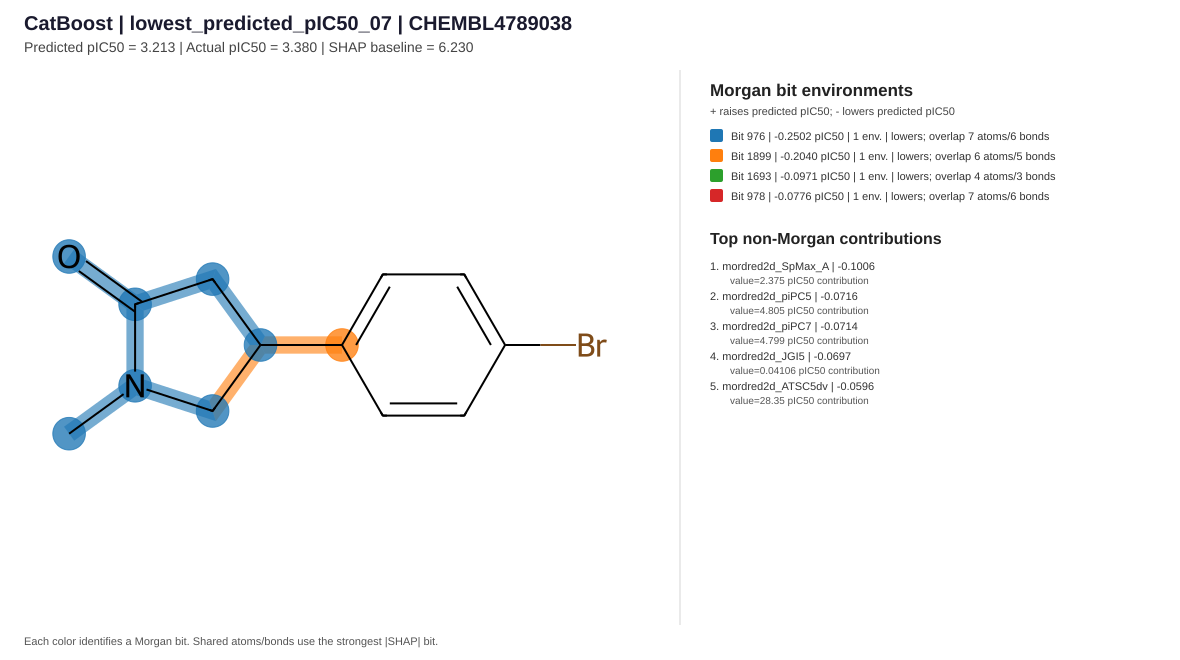

CatBoostRegressor | lowest 08/10 | rank 8/1283 | CHEMBL4791527 | predicted pIC50=3.278 | actual pIC50=3.910


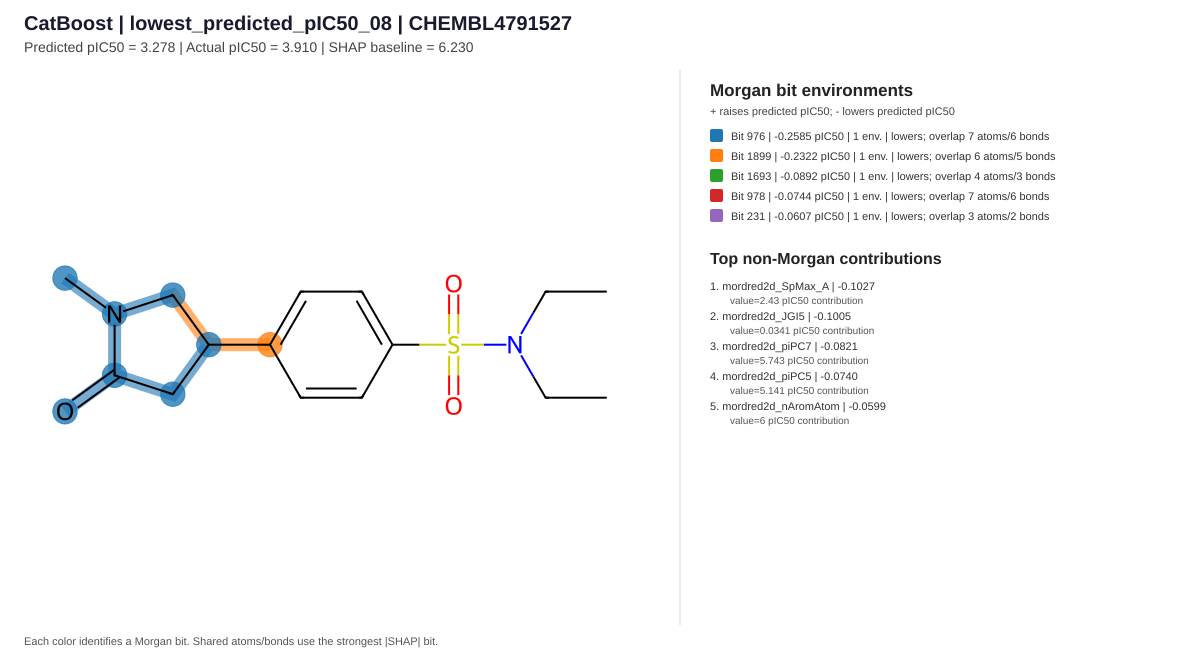

CatBoostRegressor | lowest 09/10 | rank 9/1283 | CHEMBL4742787 | predicted pIC50=3.345 | actual pIC50=3.833


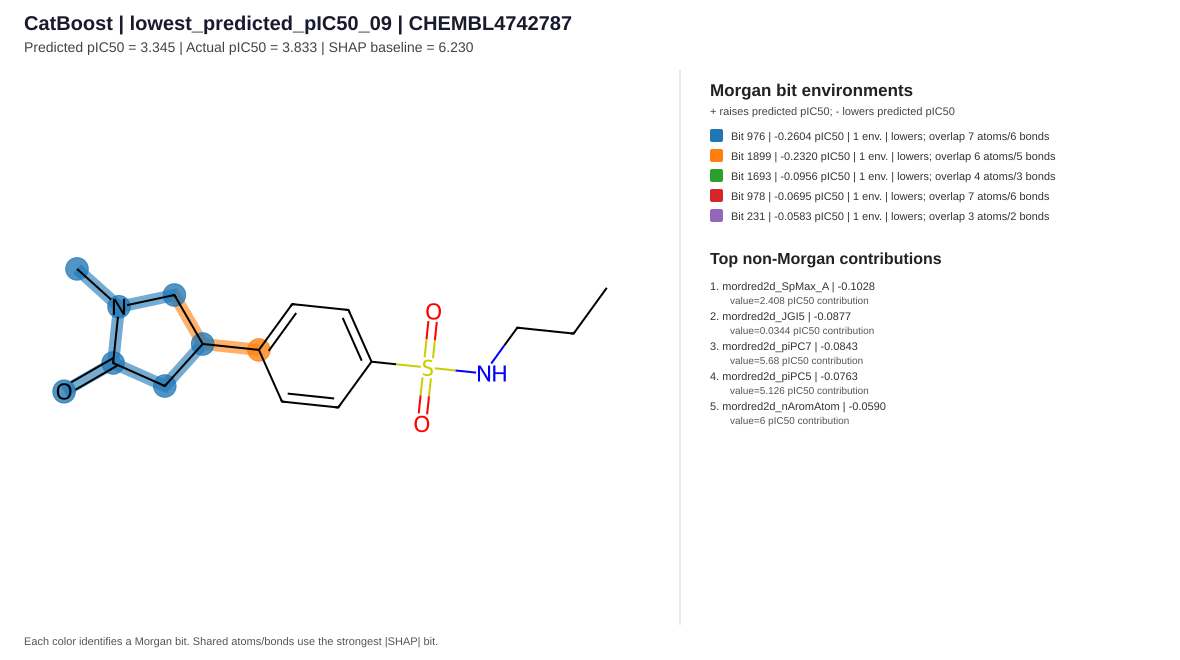

CatBoostRegressor | lowest 10/10 | rank 10/1283 | CHEMBL4763815 | predicted pIC50=3.397 | actual pIC50=3.354


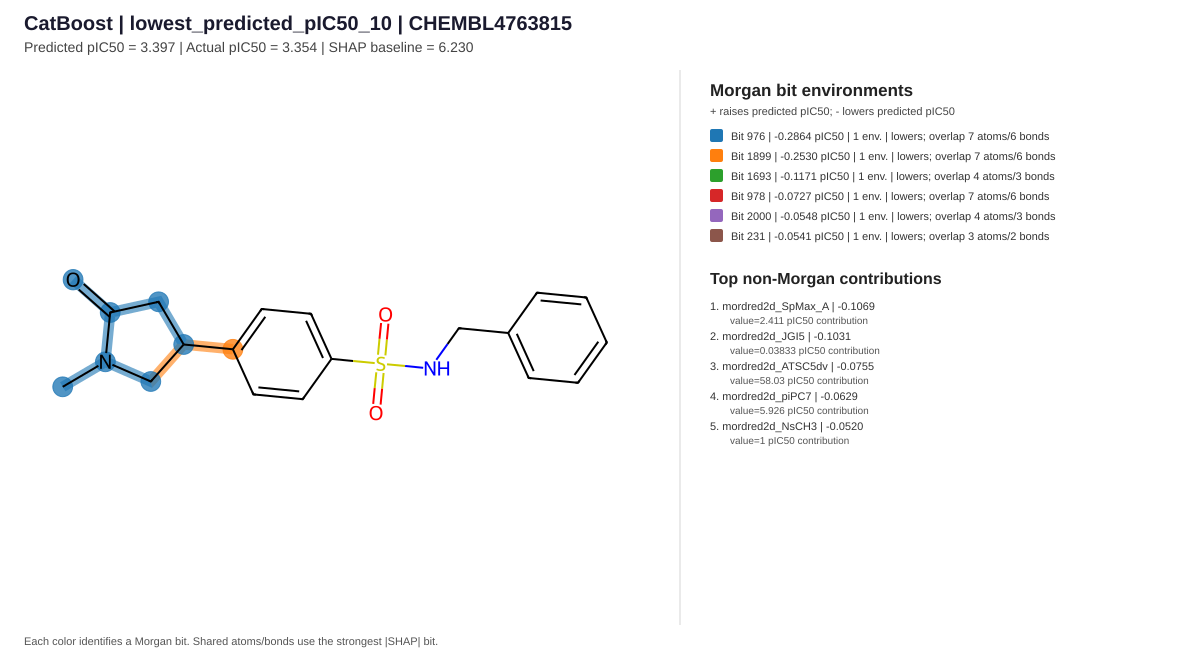

CatBoostRegressor | middle 01/10 | rank 637/1283 | CHEMBL3650881 | predicted pIC50=6.154 | actual pIC50=4.509


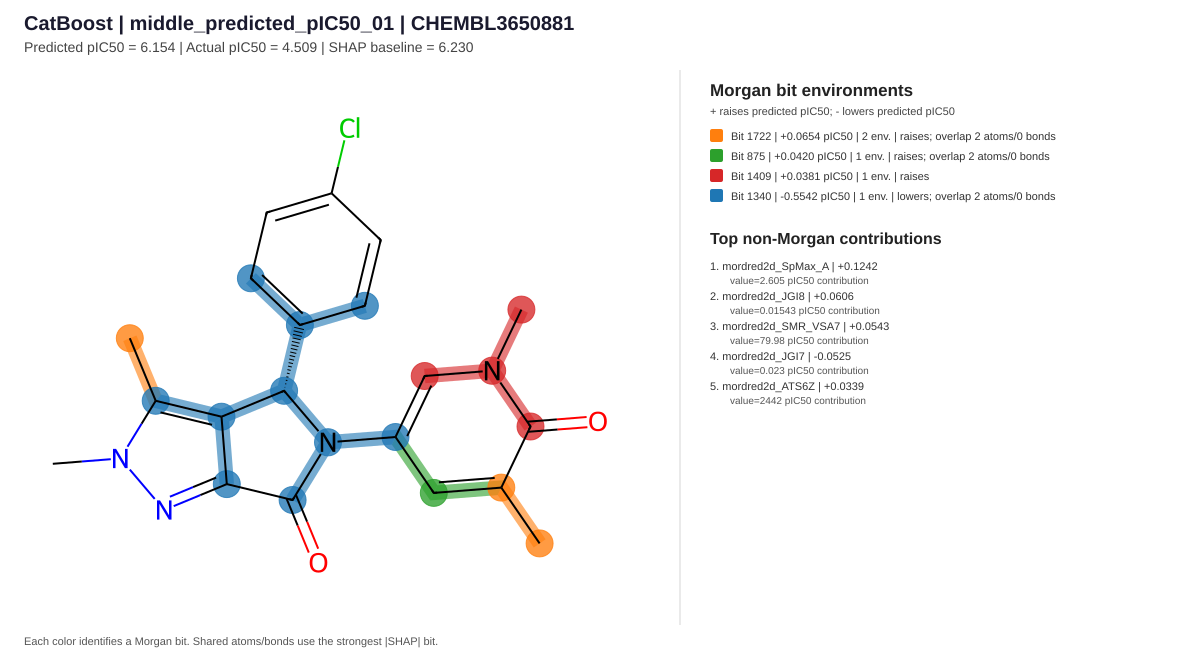

CatBoostRegressor | middle 02/10 | rank 638/1283 | CHEMBL3970467 | predicted pIC50=6.157 | actual pIC50=5.750


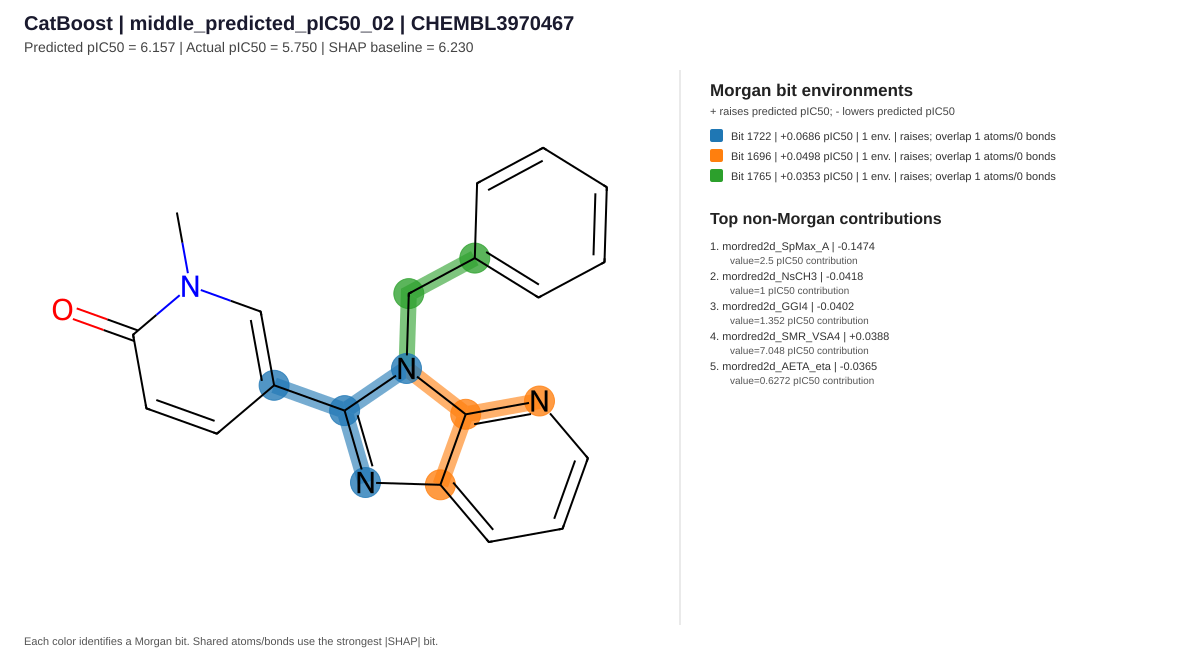

CatBoostRegressor | middle 03/10 | rank 639/1283 | CHEMBL5271781 | predicted pIC50=6.161 | actual pIC50=5.886


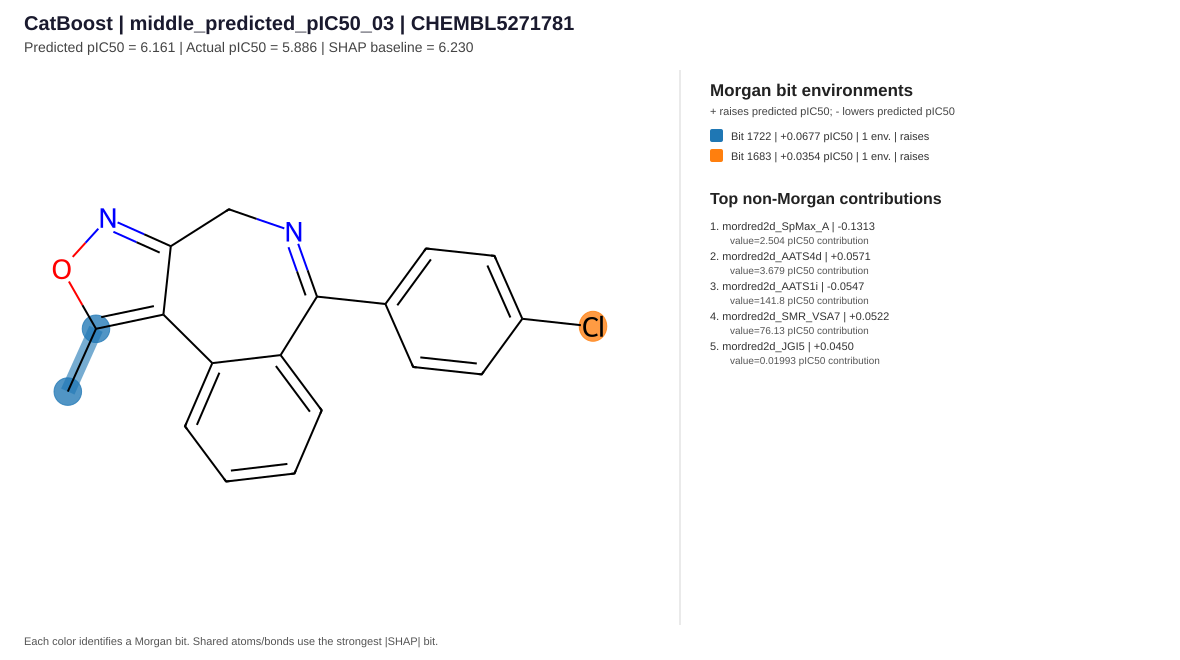

CatBoostRegressor | middle 04/10 | rank 640/1283 | CHEMBL5933781 | predicted pIC50=6.163 | actual pIC50=5.561


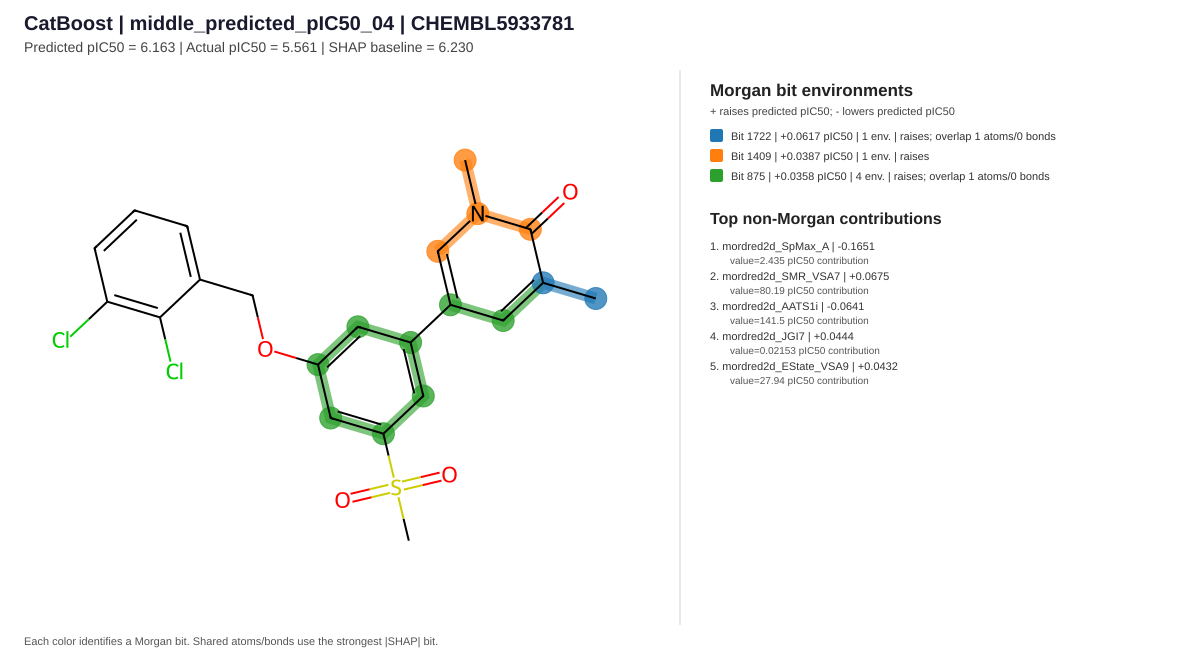

CatBoostRegressor | middle 05/10 | rank 641/1283 | CHEMBL2430887 | predicted pIC50=6.164 | actual pIC50=5.200


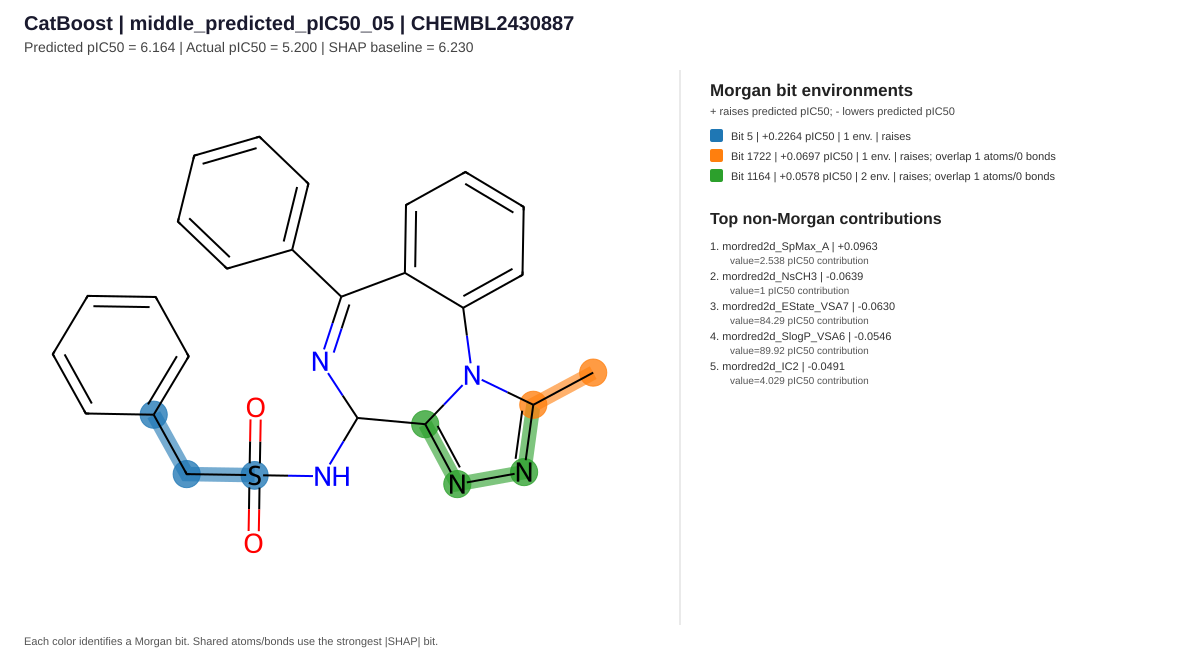

CatBoostRegressor | middle 06/10 | rank 642/1283 | CHEMBL4848969 | predicted pIC50=6.164 | actual pIC50=6.100


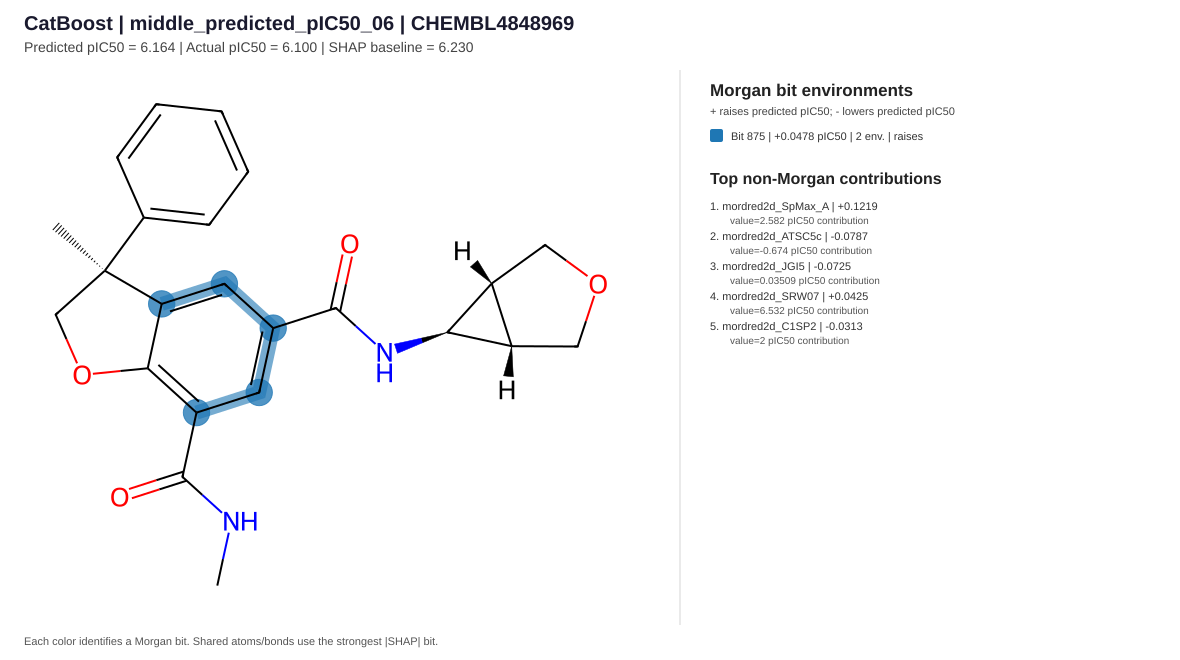

CatBoostRegressor | middle 07/10 | rank 643/1283 | CHEMBL4211868 | predicted pIC50=6.176 | actual pIC50=6.850


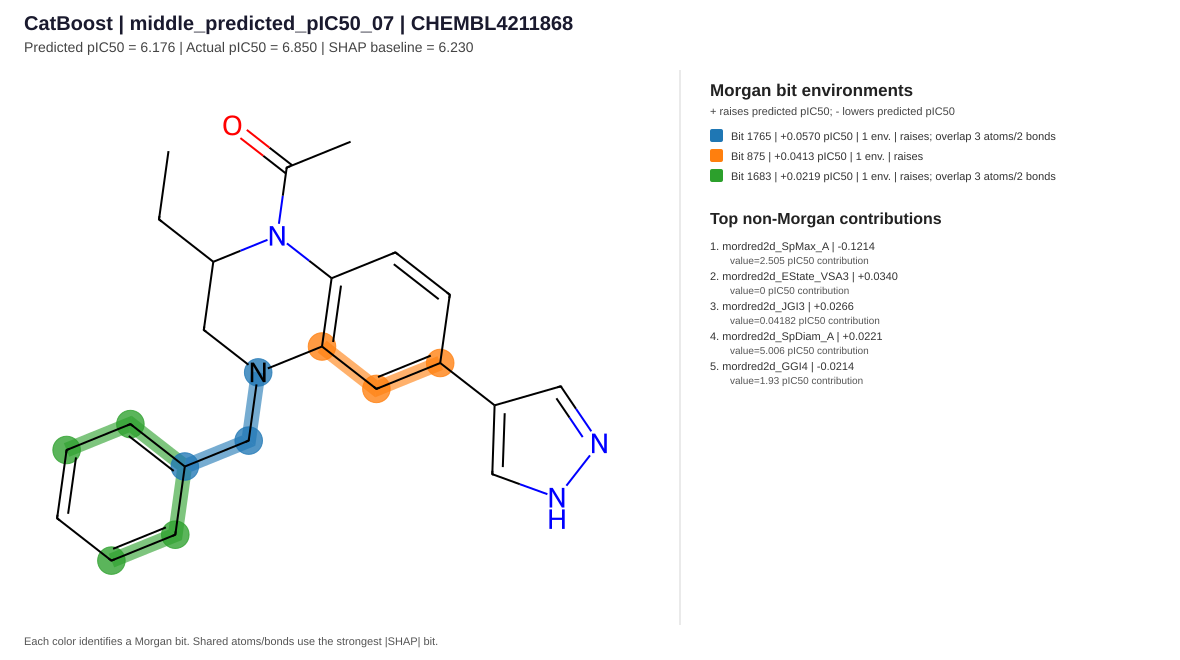

CatBoostRegressor | middle 08/10 | rank 644/1283 | CHEMBL5560243 | predicted pIC50=6.179 | actual pIC50=6.750


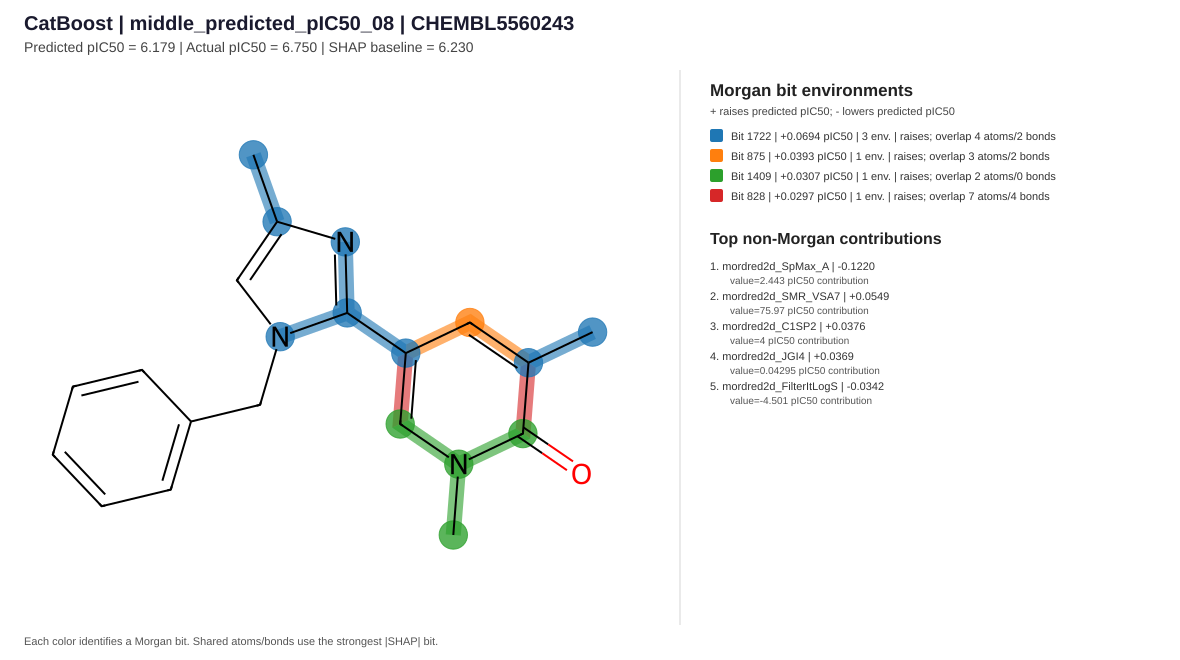

CatBoostRegressor | middle 09/10 | rank 645/1283 | CHEMBL5788096 | predicted pIC50=6.184 | actual pIC50=6.041


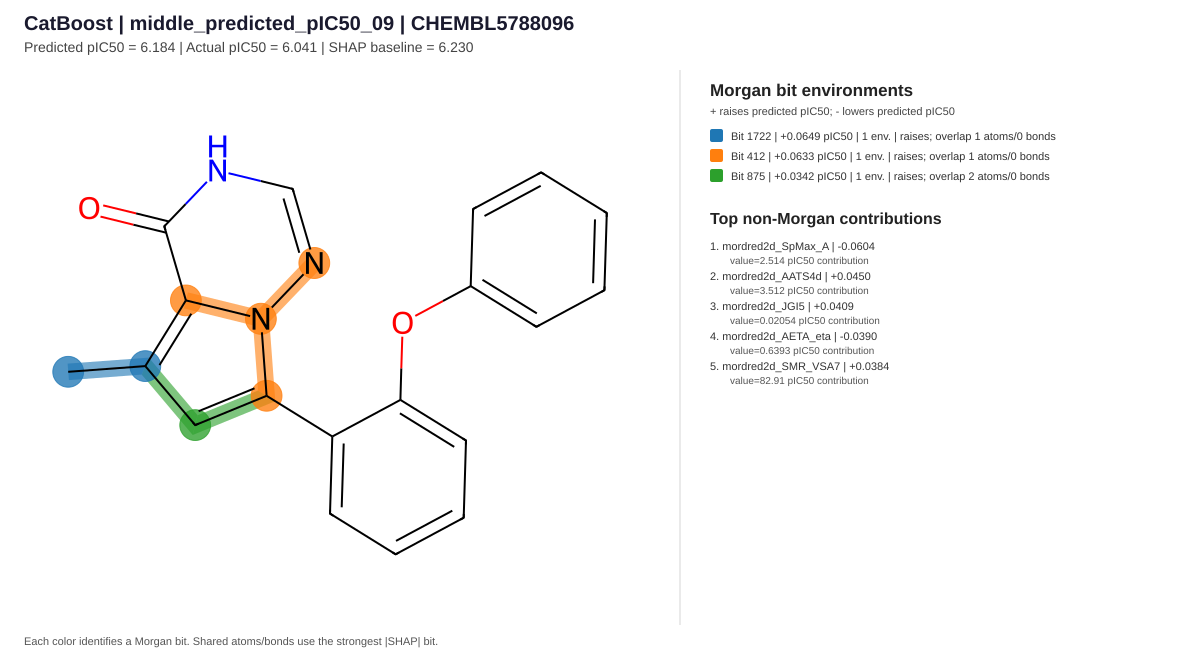

CatBoostRegressor | middle 10/10 | rank 646/1283 | CHEMBL5740655 | predicted pIC50=6.187 | actual pIC50=6.260


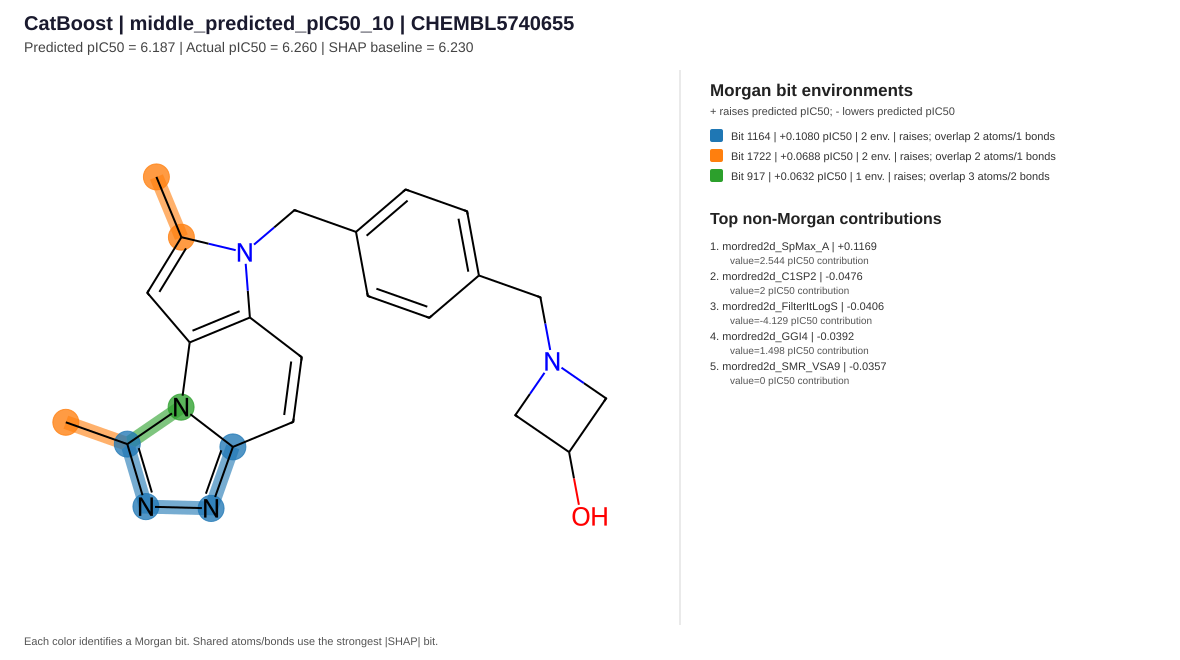

CatBoostRegressor | highest 01/10 | rank 1274/1283 | CHEMBL5176955 | predicted pIC50=8.681 | actual pIC50=9.338


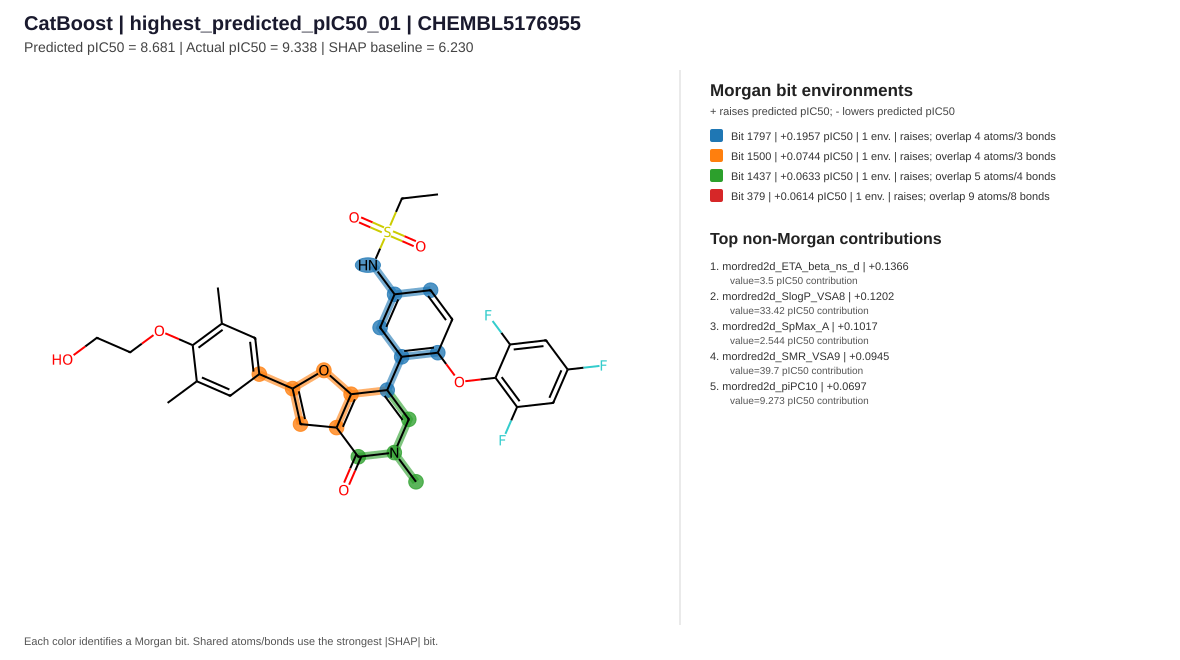

CatBoostRegressor | highest 02/10 | rank 1275/1283 | CHEMBL5200542 | predicted pIC50=8.690 | actual pIC50=9.237


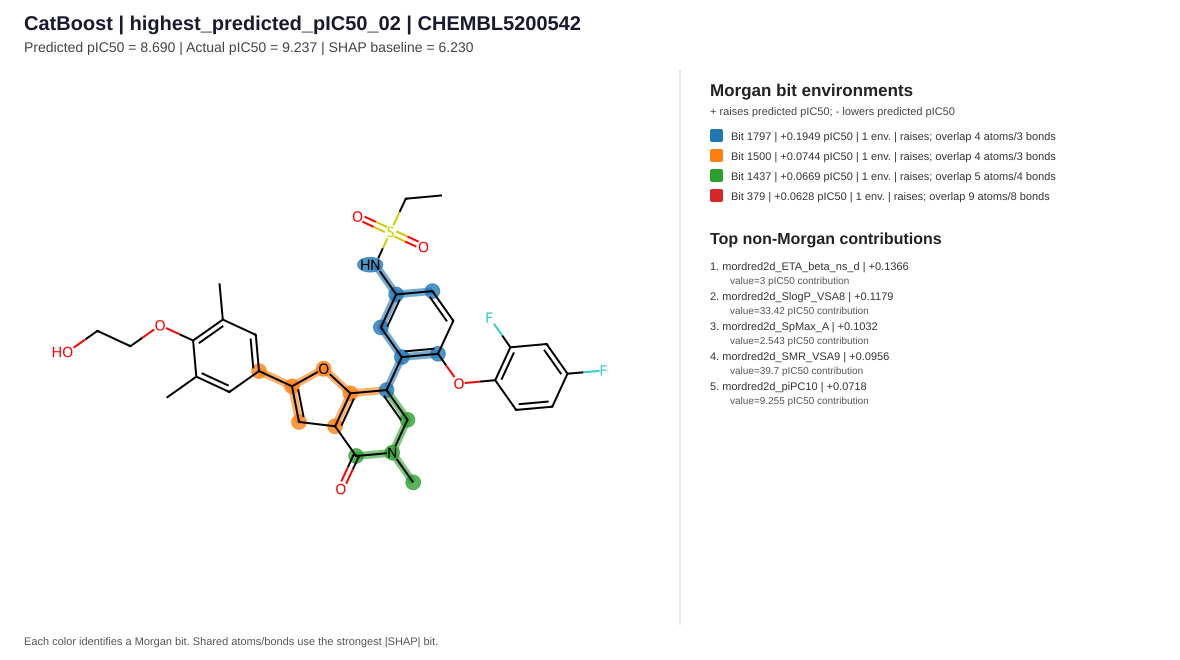

CatBoostRegressor | highest 03/10 | rank 1276/1283 | CHEMBL5206375 | predicted pIC50=8.756 | actual pIC50=9.312


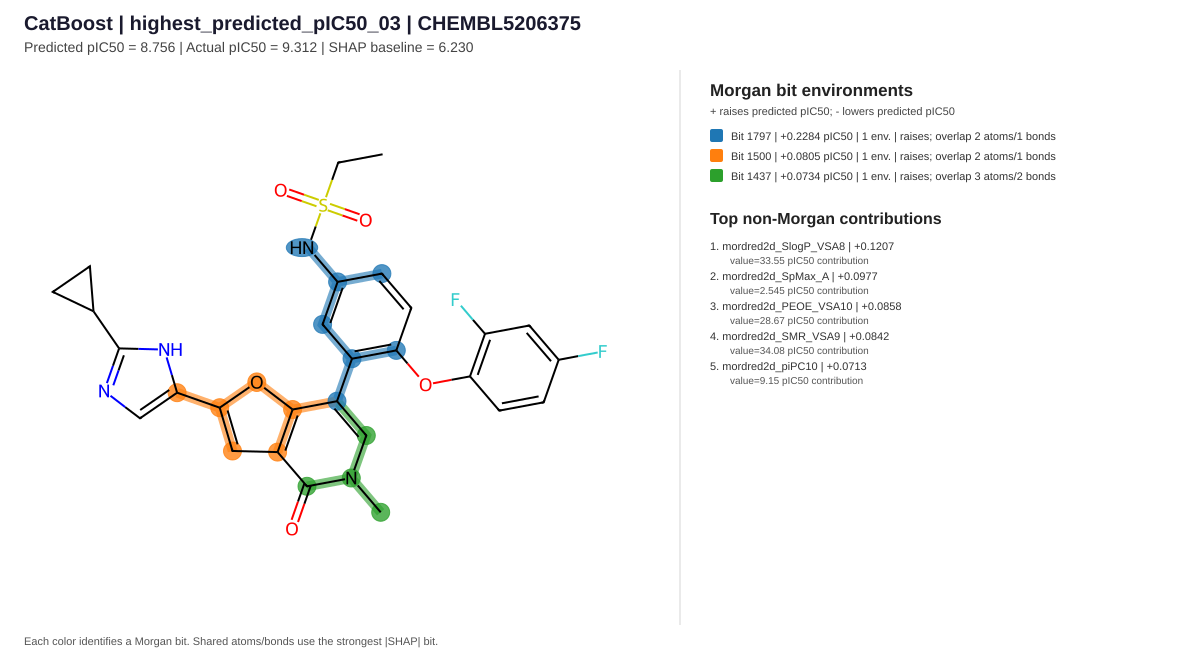

CatBoostRegressor | highest 04/10 | rank 1277/1283 | CHEMBL6008826 | predicted pIC50=8.786 | actual pIC50=7.770


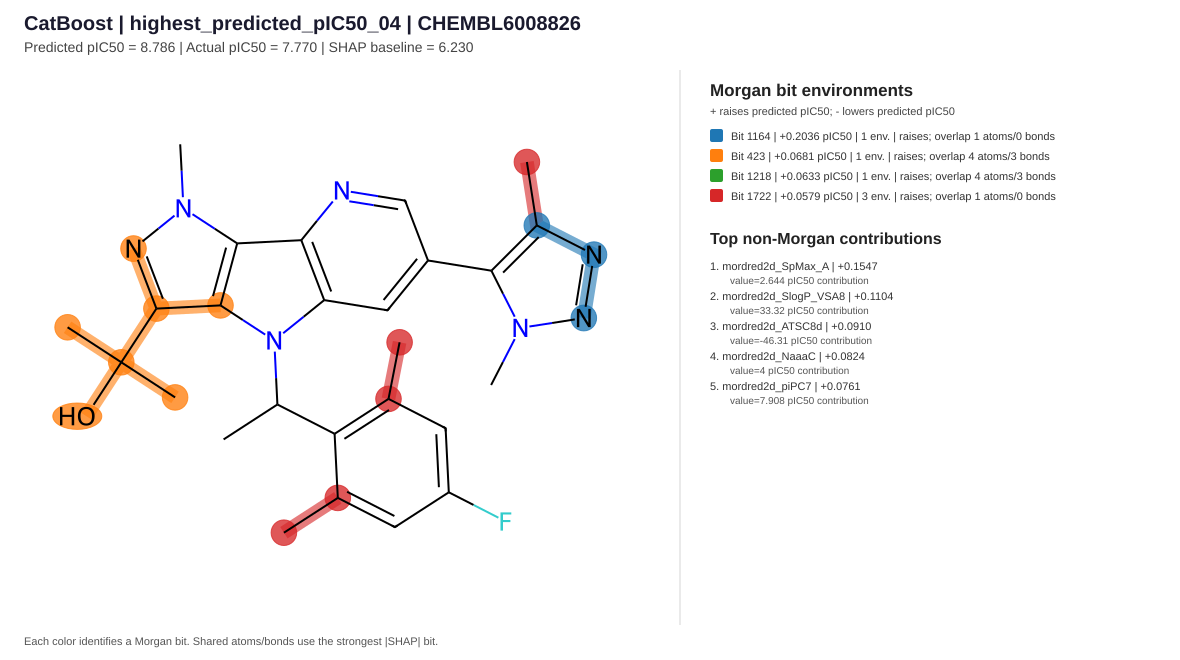

CatBoostRegressor | highest 05/10 | rank 1278/1283 | CHEMBL5173301 | predicted pIC50=8.828 | actual pIC50=8.863


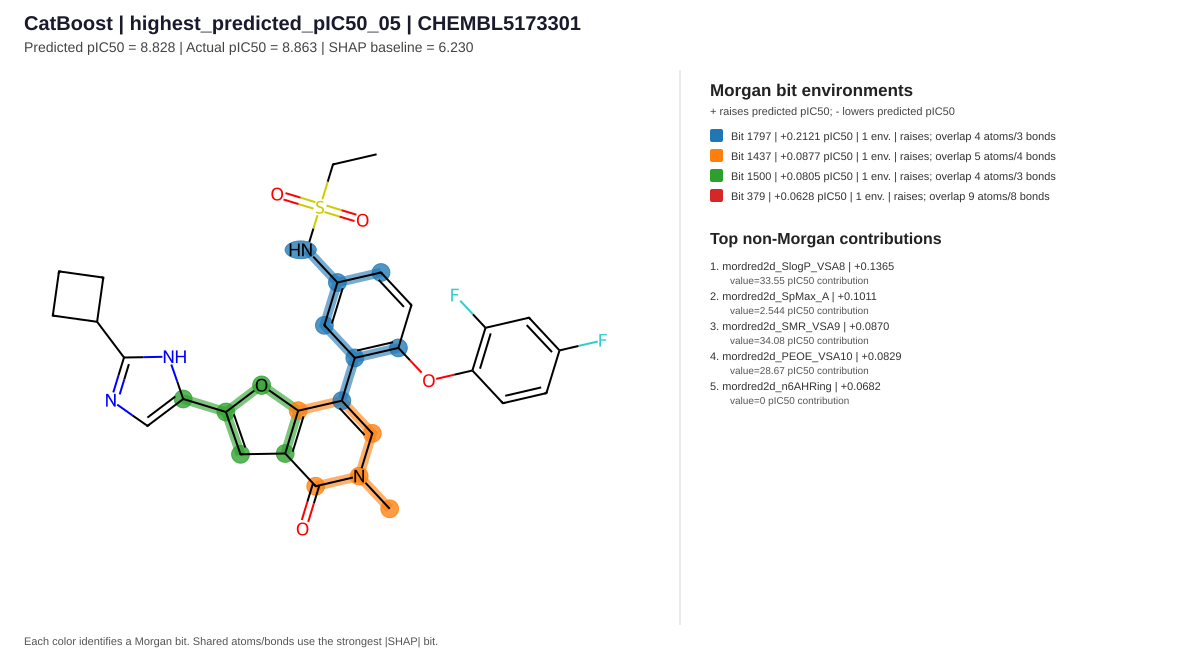

CatBoostRegressor | highest 06/10 | rank 1279/1283 | CHEMBL5980250 | predicted pIC50=8.834 | actual pIC50=9.469


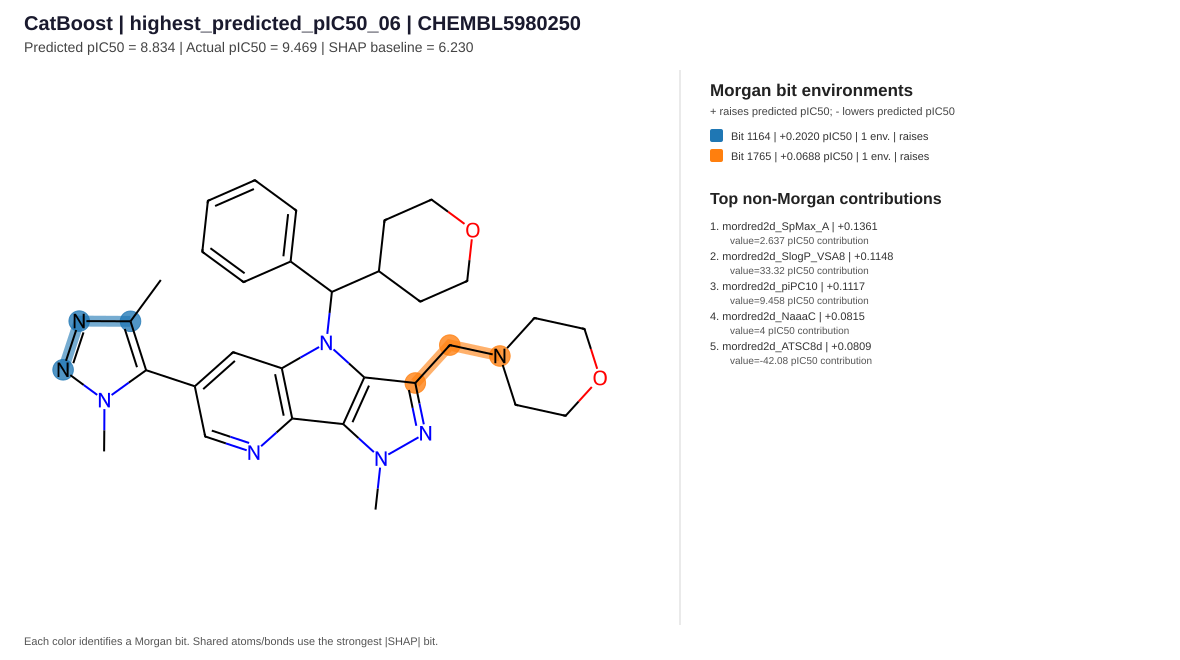

CatBoostRegressor | highest 07/10 | rank 1280/1283 | CHEMBL6021830 | predicted pIC50=9.000 | actual pIC50=9.180


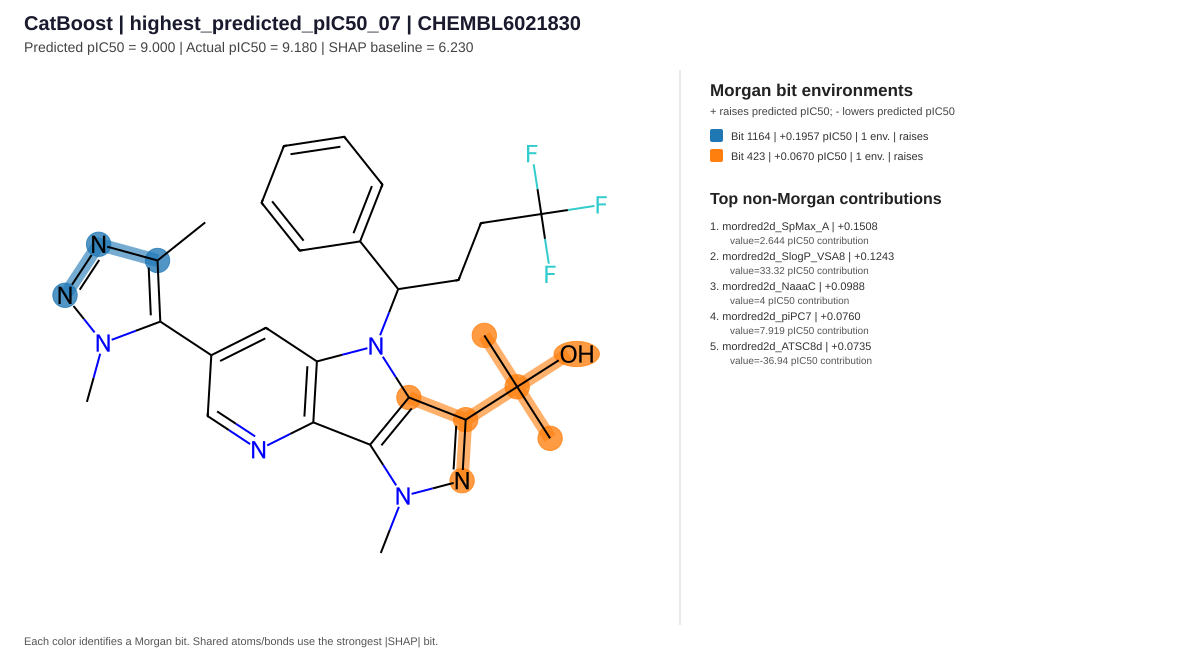

CatBoostRegressor | highest 08/10 | rank 1281/1283 | CHEMBL5883744 | predicted pIC50=9.000 | actual pIC50=8.796


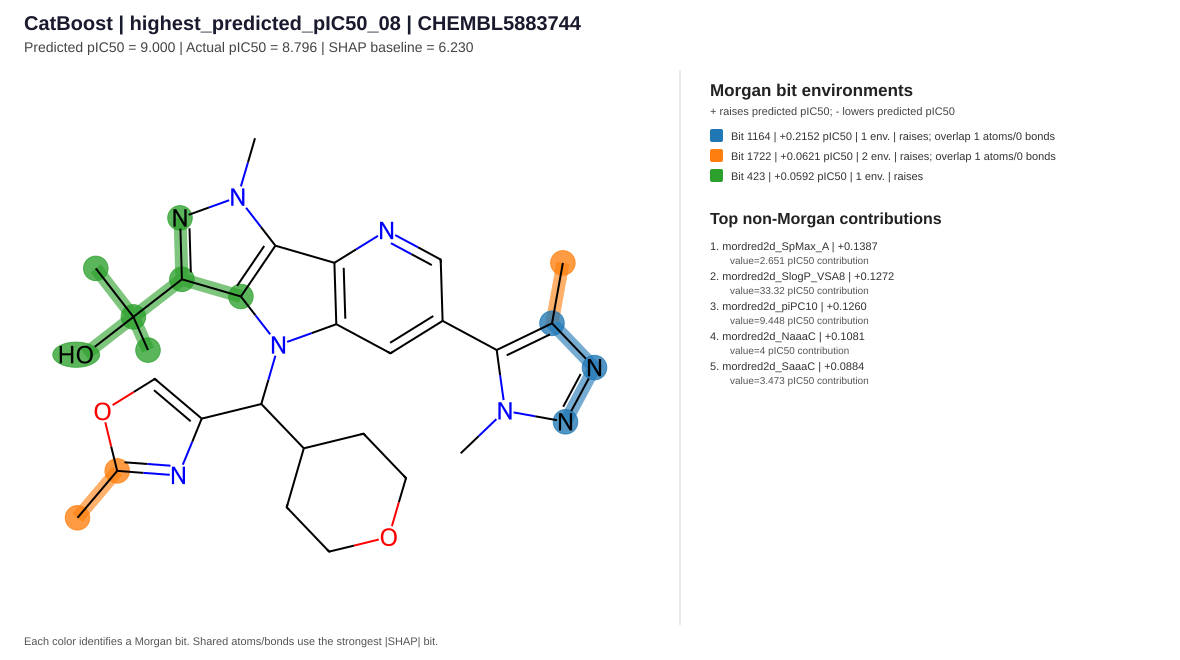

CatBoostRegressor | highest 09/10 | rank 1282/1283 | CHEMBL6010533 | predicted pIC50=9.087 | actual pIC50=8.337


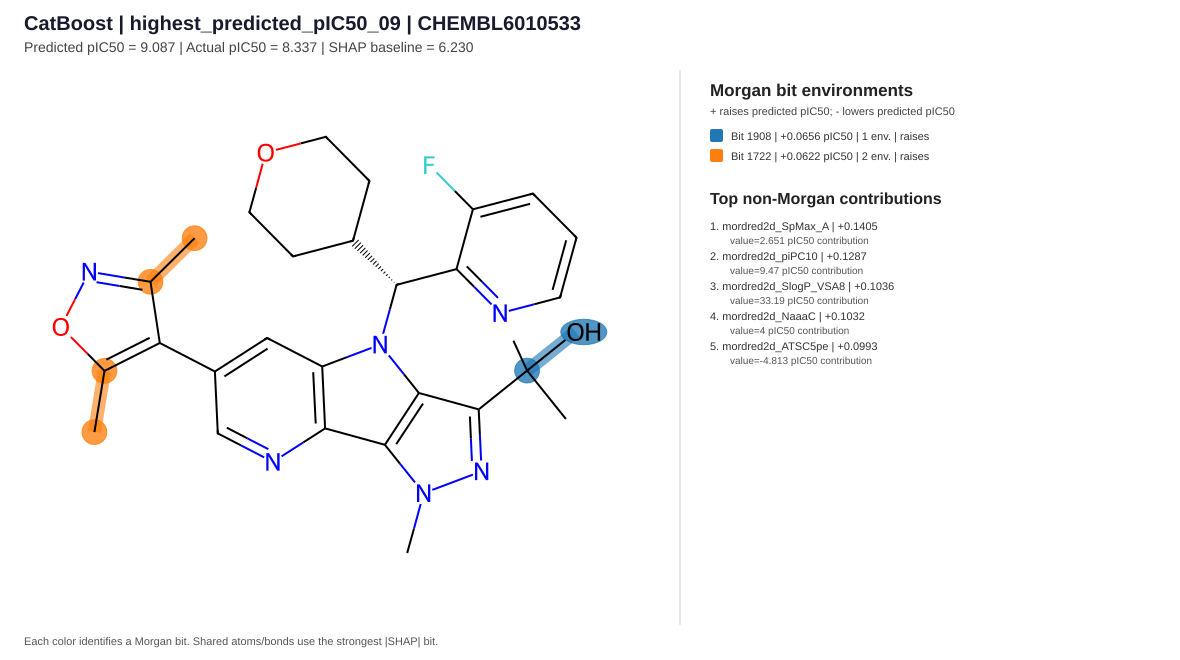

CatBoostRegressor | highest 10/10 | rank 1283/1283 | CHEMBL6051531 | predicted pIC50=9.237 | actual pIC50=9.310


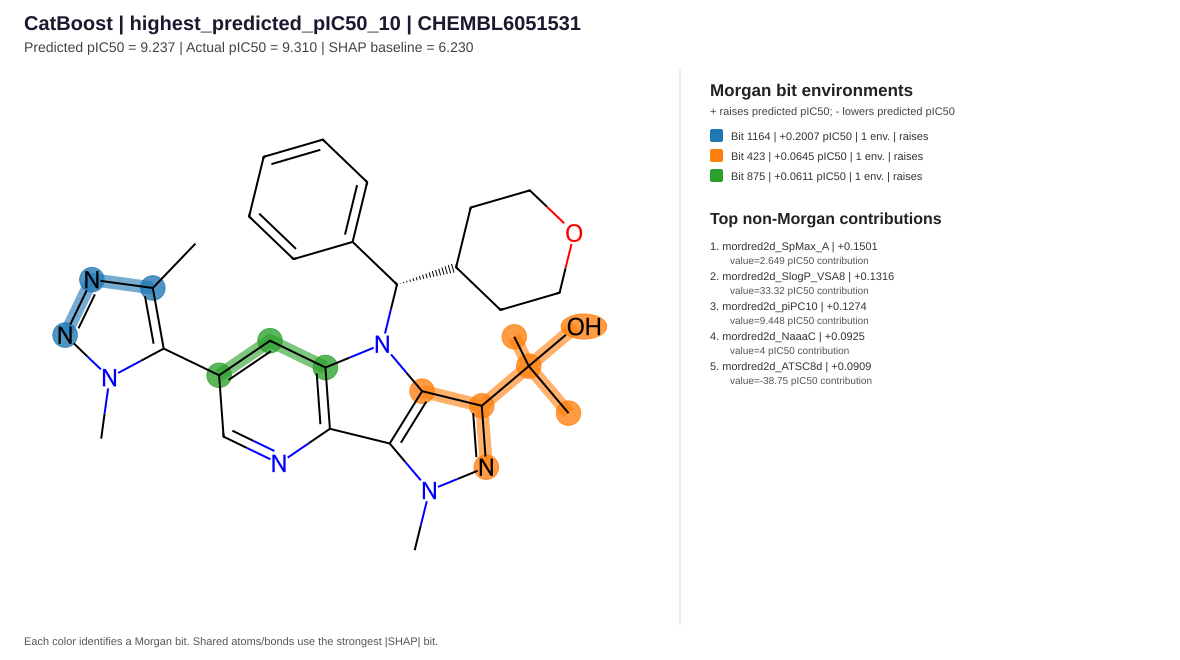

,model,group,case,rank_within_group,prediction_rank,chembl_id,predicted_pIC50,actual_pIC50,shap_baseline,top_n_features,n_morgan_bits_mapped,figure_svg,figure_png
0,CatBoostRegressor,lowest,lowest_predicted_pIC50_01,1,1,CHEMBL4748673,2.993360,3.493495,6.229571,12,5,C:\Users\USER\Documents\E\Code\outputs\10c_mol...,C:\Users\USER\Documents\E\Code\outputs\10c_mol...
1,CatBoostRegressor,lowest,lowest_predicted_pIC50_02,2,2,CHEMBL4788775,3.032347,2.943095,6.229571,12,4,C:\Users\USER\Documents\E\Code\outputs\10c_mol...,C:\Users\USER\Documents\E\Code\outputs\10c_mol...
2,CatBoostRegressor,lowest,lowest_predicted_pIC50_03,3,3,CHEMBL4764375,3.032347,2.844664,6.229571,12,4,C:\Users\USER\Documents\E\Code\outputs\10c_mol...,C:\Users\USER\Documents\E\Code\outputs\10c_mol...
3,CatBoostRegressor,lowest,lowest_predicted_pIC50_04,4,4,CHEMBL4792834,3.101889,3.185752,6.229571,12,6,C:\Users\USER\Documents\E\Code\outputs\10c_mol...,C:\Users\USER\Documents\E\Code\outputs\10c_mol...
4,CatBoostRegressor,lowest,lowest_predicted_pIC50_05,5,5,CHEMBL4751250,3.119276,3.602060,6.229571,12,4,C:\Users\USER\Documents\E\Code\outputs\10c_mol...,C:\Users\USER\Documents\E\Code\outputs\10c_mol...
5,CatBoostRegressor,lowest,lowest_predicted_pIC50_06,6,6,CHEMBL4747961,3.191523,3.872895,6.229571,12,5,C:\Users\USER\Documents\E\Code\outputs\10c_mol...,C:\Users\USER\Documents\E\Code\outputs\10c_mol...
6,CatBoostRegressor,lowest,lowest_predicted_pIC50_07,7,7,CHEMBL4789038,3.213398,3.379864,6.229571,12,4,C:\Users\USER\Documents\E\Code\outputs\10c_mol...,C:\Users\USER\Documents\E\Code\outputs\10c_mol...
7,CatBoostRegressor,lowest,lowest_predicted_pIC50_08,8,8,CHEMBL4791527,3.277840,3.910095,6.229571,12,5,C:\Users\USER\Documents\E\Code\outputs\10c_mol...,C:\Users\USER\Documents\E\Code\outputs\10c_mol...
8,CatBoostRegressor,lowest,lowest_predicted_pIC50_09,9,9,CHEMBL4742787,3.345486,3.832683,6.229571,12,5,C:\Users\USER\Documents\E\Code\outputs\10c_mol...,C:\Users\USER\Documents\E\Code\outputs\10c_mol...
9,CatBoostRegressor,lowest,lowest_predicted_pIC50_10,10,10,CHEMBL4763815,3.397071,3.353596,6.229571,12,6,C:\Users\USER\Documents\E\Code\outputs\10c_mol...,C:\Users\USER\Documents\E\Code\outputs\10c_mol...


Saved 30 SVG and 300-dpi PNG figures for CatBoostRegressor under C:\Users\USER\Documents\E\Code\outputs\10c_molecular_highlighting\figures
CatBoost: all 30 figures and tables saved.
Both final models now have 10 lowest, 10 median-centered, and 10 highest prediction examples.


In [21]:
# 6. Create and display 30 CatBoost molecular SHAP examples.
cat_cases, cat_top_features, cat_environments = render_model_cases(
    "CatBoostRegressor"
)
print("CatBoost: all 30 figures and tables saved.")
print("Both final models now have 10 lowest, 10 median-centered, and 10 highest prediction examples.")


In [22]:
# 7. Review the 60 selected molecules and saved files.
from src.utils import write_manifest

all_cases = pd.concat([et_cases, cat_cases], ignore_index=True)
all_top_features = pd.concat(
    [et_top_features, cat_top_features], ignore_index=True
)
all_environments = pd.concat(
    [et_environments, cat_environments], ignore_index=True
)

all_cases.to_csv(
    TABLE_DIR / "molecular_SHAP_cases_both_models.csv",
    index=False,
)
all_top_features.to_csv(
    TABLE_DIR / "molecular_SHAP_top_features_both_models.csv",
    index=False,
)
all_environments.to_csv(
    TABLE_DIR / "molecular_SHAP_mapped_environments_both_models.csv",
    index=False,
)

case_summary = (
    all_cases.groupby(["model", "group"], sort=False)
    .agg(
        n_molecules=("chembl_id", "nunique"),
        minimum_predicted_pIC50=("predicted_pIC50", "min"),
        maximum_predicted_pIC50=("predicted_pIC50", "max"),
    )
    .reset_index()
)

display(case_summary)
display(
    all_cases[
        [
            "model",
            "group",
            "rank_within_group",
            "prediction_rank",
            "chembl_id",
            "predicted_pIC50",
            "actual_pIC50",
            "n_morgan_bits_mapped",
        ]
    ]
)

files = sorted(
    p for p in OUT_DIR.rglob("*")
    if p.is_file() and p.name != "manifest.json"
)
file_inventory = pd.DataFrame(
    [
        {
            "file": str(p.relative_to(OUT_DIR)),
            "size_kB": round(p.stat().st_size / 1024, 1),
        }
        for p in files
    ]
)
display(file_inventory)

write_manifest(
    "10c_molecular_highlighting",
    {
        "feature_set": "exact fixed 250 Stage 05 feature list",
        "models": MODELS,
        "source_shap": "saved Stage 10 SHAP values for final Stage 08 models",
        "local_cases": (
            "For each model, 10 lowest predictions, 10 consecutive "
            "median-centered predictions, and 10 highest predictions among "
            "locked test molecules; selected using predictions only"
        ),
        "actual_test_activity_loaded": True,
        "actual_activity_source": "observed_pIC50 column in Stage 08 locked-test prediction table",
        "actual_activity_use": "display and table reporting only; not used for example selection, model fitting, or tuning",
        "selection_uses_actual_activity": False,
        "feature_values": "only the fixed 250 Stage 05 columns were read from Stage 03 parquet",
        "morgan": {
            "radius": FP_RADIUS,
            "bits": FP_SIZE,
            "include_chirality": USE_CHIRALITY,
        },
        "highlight_rule": (
            "top 12 absolute SHAP features; present Morgan bit environments "
            "mapped to RDKit atom/bond environments; unique color per Morgan "
            "bit; direction, environment count, and overlap counts recorded "
            "in the figure legend and mapping table; overlapping atoms/bonds "
            "use the bit with strongest absolute SHAP value"
        ),
        "non_morgan_descriptors": (
            "strongest available non-Morgan SHAP contributions listed beside molecule"
        ),
    },
    inputs=[
        SELECTED_FILE,
        TEST_IDS_FILE,
        CLEANED_FILE,
        FEATURES_FILE,
        PREDICTIONS_FILE,
    ] + [
        SHAP_DIR / "tables" / f"test_shap_values_{m}.parquet"
        for m in MODELS
    ],
    outputs=files + [
        TABLE_DIR / "molecular_SHAP_cases_both_models.csv",
        TABLE_DIR / "molecular_SHAP_top_features_both_models.csv",
        TABLE_DIR / "molecular_SHAP_mapped_environments_both_models.csv",
    ],
)

n_svg = len(list(FIGURE_DIR.glob("*.svg")))
n_png = len(list(FIGURE_DIR.glob("*.png")))
print(f"Stage 10C complete: {len(all_cases)} molecule cases.")
print(f"Saved {n_svg} SVG and {n_png} PNG figures.")
print(f"Output folder: {OUT_DIR}")


,model,group,n_molecules,minimum_predicted_pIC50,maximum_predicted_pIC50
0,ExtraTreesRegressor,lowest,10,3.210712,3.676065
1,ExtraTreesRegressor,middle,10,6.173584,6.185781
2,ExtraTreesRegressor,highest,10,8.810973,9.272691
3,CatBoostRegressor,lowest,10,2.993360,3.397071
4,CatBoostRegressor,middle,10,6.154259,6.187193
5,CatBoostRegressor,highest,10,8.681257,9.236537


,model,group,rank_within_group,prediction_rank,chembl_id,predicted_pIC50,actual_pIC50,n_morgan_bits_mapped
0,ExtraTreesRegressor,lowest,1,1,CHEMBL4763815,3.210712,3.353596,7
1,ExtraTreesRegressor,lowest,2,2,CHEMBL4759311,3.231659,3.325139,7
2,ExtraTreesRegressor,lowest,3,3,CHEMBL4788775,3.329511,2.943095,6
3,ExtraTreesRegressor,lowest,4,4,CHEMBL4764375,3.329511,2.844664,6
4,ExtraTreesRegressor,lowest,5,5,CHEMBL4792834,3.360000,3.185752,8
5,ExtraTreesRegressor,lowest,6,6,CHEMBL4751250,3.488187,3.602060,7
6,ExtraTreesRegressor,lowest,7,7,CHEMBL4742787,3.491378,3.832683,7
7,ExtraTreesRegressor,lowest,8,8,CHEMBL4791527,3.506934,3.910095,8
8,ExtraTreesRegressor,lowest,9,9,CHEMBL4747961,3.518601,3.872895,7
9,ExtraTreesRegressor,lowest,10,10,CHEMBL4789038,3.676065,3.379864,7


,file,size_kB
0,figures\molecular_SHAP_CatBoostRegressor_highe...,75.1
1,figures\molecular_SHAP_CatBoostRegressor_highe...,35.7
2,figures\molecular_SHAP_CatBoostRegressor_highe...,74.1
3,figures\molecular_SHAP_CatBoostRegressor_highe...,35.3
4,figures\molecular_SHAP_CatBoostRegressor_highe...,78.1
...,...,...
124,tables\molecular_SHAP_mapped_environments_CatB...,16.0
125,tables\molecular_SHAP_mapped_environments_Extr...,24.7
126,tables\molecular_SHAP_top_features_both_models...,79.0
127,tables\molecular_SHAP_top_features_CatBoost.csv,40.2


Stage 10C complete: 60 molecule cases.
Saved 60 SVG and 60 PNG figures.
Output folder: C:\Users\USER\Documents\E\Code\outputs\10c_molecular_highlighting


## How to read the images

- The notebook shows 10 lowest-prediction, 10 median-centered, and 10 highest-prediction molecules for each model: 30 examples per model, 60 total.
- Each mapped Morgan bit among the strongest local SHAP features gets its own color. Its legend entry gives the bit number, signed SHAP contribution, direction, and number of mapped environments.
- Positive (`+`) SHAP contributions raise the predicted pIC50; negative (`-`) contributions lower it.
- The right panel lists the strongest available non-Morgan feature contributions beside the molecule.
- Where environments overlap, the shared atom or bond is colored for the bit with the largest absolute SHAP value; overlap counts are saved in the mapping table.
- Morgan fingerprints are hashed, so a bit can correspond to more than one atom environment. The environment table records the bit and the atom/bond indices used in the drawing.
- Actual pIC50 is shown beside predicted pIC50 using the observed values saved by Stage 08. Examples are selected using predicted pIC50 only; actual activity is for reporting and does not affect selection. The notebook does not refit models or change the fixed Stage 05 feature list.
